# Exploratory Data Analysis of E-commerce Sales and Customer Behaviour

**Track 2: Data Science** &nbsp;|&nbsp; **Prepared by:** Solomon Buba Tarfa &nbsp;|&nbsp; **Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, SciPy

---

## Business objective
Investigate customer behaviour, sales patterns and business performance using statistical and exploratory data analysis techniques, for an online retailer of plush toys ("Fuzzy Factory") that sells four products.

## Datasets used
| File | Grain (one row =) | Key columns |
|---|---|---|
| `website_sessions.csv` | one website visit | `website_session_id`, `user_id`, `utm_source`, `device_type`, `is_repeat_session` |
| `website_pageviews.csv` | one page viewed in a session | `website_pageview_id`, `website_session_id`, `pageview_url` |
| `orders_mav.csv` | one customer order | `order_id`, `website_session_id`, `items_purchased`, `price_usd`, `cogs_usd` |
| `order_items.csv` | one product line in an order | `order_item_id`, `order_id`, `product_id`, `is_primary_item` |
| `order_item_refunds.csv` | one refunded product line | `order_item_id`, `refund_amount_usd` |
| `products.csv` | one product | `product_id`, `product_name` |

## Structure of this notebook
1. **Task 1 - Data exploration:** load, inspect, quality-check, relate and clean the data
2. **Task 2 - Exploratory data analysis:** the eight business questions
3. **Task 3 - Statistical analysis and visualisation:** descriptive statistics, relationships, period comparisons, hypothesis tests
4. **Task 4 - Interpretation and recommendations:** evidence-based business insights

## 0. Setup
Import the libraries, set display options and define small helper functions used throughout the notebook.

In [1]:
# Import the operating-system module to build file paths that work on any computer
import os
# Import warnings so that harmless library warnings do not clutter the output
import warnings
# Import json so key results can be saved to a file at the end
import json
# Import pandas, the main library for tabular data
import pandas as pd
# Import NumPy for fast numerical operations
import numpy as np
# Import Matplotlib's plotting interface to draw charts
import matplotlib.pyplot as plt
# Import Seaborn for attractive statistical charts built on Matplotlib
import seaborn as sns
# Import the SciPy statistics module for hypothesis tests and correlations
from scipy import stats

# Use IPython's display() to show tables nicely in Jupyter/Colab
try:
    # Try to import the rich display function
    from IPython.display import display
# If IPython is not installed (plain Python script), fall back to print
except ImportError:
    # print is a simple replacement for display
    display = print

# Folder containing the six CSV files ("." means the same folder as this notebook)
DATA_DIR = os.environ.get("DATA_DIR", ".")
# Folder where every chart will be saved as a PNG image
FIG_DIR = os.environ.get("FIG_DIR", "figures")
# Create the chart folder if it does not exist yet
os.makedirs(FIG_DIR, exist_ok=True)

# Hide non-critical warnings to keep the output clean
warnings.filterwarnings("ignore")
# Apply a clean, light Seaborn theme to every chart
sns.set_theme(style="whitegrid", context="notebook")
# Set a sharp resolution for charts shown in the notebook
plt.rcParams["figure.dpi"] = 110
# Remove the top and right chart borders for a modern look
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# Show numbers in pandas tables with thousands separators and 2 decimals
pd.set_option("display.float_format", "{:,.2f}".format)
# Allow pandas tables to use a wider screen area
pd.set_option("display.width", 170)
# Show up to 30 columns before pandas truncates a table
pd.set_option("display.max_columns", 30)

# Consistent colour palette used for products and categories in every chart
PALETTE = ["#1F4E79", "#2E86AB", "#F18F01", "#C73E1D", "#6A994E", "#7B2D8E", "#8D99AE"]
# Dictionary that will hold the key numbers quoted in the final report
M = {}
# Helper that formats a number as US dollars without decimals
money = lambda x: f"${x:,.0f}"
# Helper that formats a fraction (0.0683) as a percentage string ("6.8%")
pct = lambda x, d=1: f"{x * 100:.{d}f}%"

def save_fig(name):
    """Tidy the layout, save the current figure as a PNG and display it."""
    # Adjust spacing so that labels and titles are not clipped
    plt.tight_layout()
    # Save the chart into the figures folder at print quality
    plt.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=150, bbox_inches="tight")
    # Display the chart in the notebook
    plt.show()

In [2]:
# Map a short dataset name to its CSV file name
FILES = {
    "sessions": "website_sessions.csv",
    "pageviews": "website_pageviews.csv",
    "orders": "orders_mav.csv",
    "order_items": "order_items.csv",
    "refunds": "order_item_refunds.csv",
    "products": "products.csv",
}
# Date format used by every created_at column (month/day/year hour:minute)
DATE_FMT = "%m/%d/%Y %H:%M"

# Read every CSV file into a dictionary of DataFrames
raw = {name: pd.read_csv(os.path.join(DATA_DIR, file)) for name, file in FILES.items()}
# Loop over each dataset to convert its text timestamps into datetime values
for name, frame in raw.items():
    # Parse the created_at text using the known format
    frame["created_at"] = pd.to_datetime(frame["created_at"], format=DATE_FMT)

# Unpack the dictionary into separate, readable variable names
sessions, pageviews, orders = raw["sessions"], raw["pageviews"], raw["orders"]
# Unpack the remaining three tables
order_items, refunds, products = raw["order_items"], raw["refunds"], raw["products"]

# Print how many rows were loaded for every dataset
for name, frame in raw.items():
    # Show the dataset name and its row count with thousands separators
    print(f"{name:<12} -> {len(frame):>9,} rows loaded")

sessions     ->   472,871 rows loaded
pageviews    -> 1,048,575 rows loaded
orders       ->    32,313 rows loaded
order_items  ->    40,025 rows loaded
refunds      ->     1,731 rows loaded
products     ->         4 rows loaded


## 1.2 Examine the shape, columns and data types

In [3]:
# Create an empty list that will collect one summary row per dataset
shape_rows = []
# Loop over every dataset
for name, frame in raw.items():
    # Store the dataset name, row count, column count, date range and memory footprint
    shape_rows.append({
        "dataset": name,
        "rows": len(frame),
        "columns": frame.shape[1],
        "first_record": frame["created_at"].min(),
        "last_record": frame["created_at"].max(),
        "memory_mb": frame.memory_usage(deep=True).sum() / 1e6,
    })
# Convert the list into a DataFrame and display it
shape_summary = pd.DataFrame(shape_rows)
# Show the shape summary
display(shape_summary)

,dataset,rows,columns,first_record,last_record,memory_mb
0,sessions,472871,9,2012-03-19 08:04:00,2015-03-19 07:59:00,147.38
1,pageviews,1048575,4,2012-03-19 08:04:00,2015-01-16 19:03:00,88.10
2,orders,32313,8,2012-03-19 10:42:00,2015-03-19 05:38:00,2.07
3,order_items,40025,7,2012-03-19 10:42:00,2015-03-19 05:38:00,2.24
4,refunds,1731,5,2012-04-06 11:32:00,2015-04-01 18:11:00,0.07
5,products,4,3,2012-03-19 08:00:00,2014-02-05 10:00:00,0.00


In [4]:
# Create an empty list that will collect one summary row per column
schema_rows = []
# Loop over every dataset
for name, frame in raw.items():
    # Loop over every column of the dataset
    for col in frame.columns:
        # Record the column's data type, number of non-null values and number of distinct values
        schema_rows.append({
            "dataset": name,
            "column": col,
            "dtype": str(frame[col].dtype),
            "non_null": int(frame[col].notna().sum()),
            "unique_values": int(frame[col].nunique()),
        })
# Convert the list into a DataFrame
schema = pd.DataFrame(schema_rows)
# Display the full schema (columns and data types of all six datasets)
display(schema)

,dataset,column,dtype,non_null,unique_values
0,sessions,website_session_id,int64,472871,472871
1,sessions,created_at,datetime64[ns],472871,367237
2,sessions,user_id,int64,472871,394318
3,sessions,is_repeat_session,int64,472871,2
4,sessions,utm_source,object,389543,3
5,sessions,utm_campaign,object,389543,4
6,sessions,utm_content,object,389543,6
7,sessions,device_type,object,472871,2
8,sessions,http_referer,object,432954,3
9,pageviews,website_pageview_id,int64,1048575,1048575


**Observations**
- The six tables describe one funnel: *sessions -> pageviews -> orders -> order items -> refunds*, plus a small product lookup table.
- Every `created_at` column is now a proper `datetime64` value, and all identifiers are integers.
- Sessions, orders and order items cover **19 Mar 2012 to 19 Mar 2015** (three years). Refunds run a little longer because they happen *after* the order.

## 1.3 Identify missing values and duplicate records

In [5]:
# Count missing values in every column of every dataset and stack the results
missing = pd.concat({name: frame.isna().sum() for name, frame in raw.items()}, names=["dataset", "column"])
# Turn the result into a tidy table with a readable column name
missing = missing.rename("missing_values").reset_index()
# Keep only the columns that actually contain missing values
missing = missing[missing["missing_values"] > 0].copy()
# Compute the percentage of rows affected in each column
missing["pct_of_rows"] = missing.apply(lambda r: r["missing_values"] / len(raw[r["dataset"]]) * 100, axis=1)
# Display the columns with missing values
display(missing)

,dataset,column,missing_values,pct_of_rows
4,sessions,utm_source,83328,17.62
5,sessions,utm_campaign,83328,17.62
6,sessions,utm_content,83328,17.62
8,sessions,http_referer,39917,8.44


In [6]:
# Define the primary key (unique identifier) of every dataset
PRIMARY_KEYS = {
    "sessions": "website_session_id",
    "pageviews": "website_pageview_id",
    "orders": "order_id",
    "order_items": "order_item_id",
    "refunds": "order_item_refund_id",
    "products": "product_id"
}
# Create an empty list for the duplicate-check results
dup_rows = []
# Loop over every dataset and its primary key
for name, key in PRIMARY_KEYS.items():
    # Count fully identical rows and repeated primary-key values
    dup_rows.append({
        "dataset": name,
        "fully_duplicated_rows": int(raw[name].duplicated().sum()),
        "duplicated_primary_keys": int(raw[name][key].duplicated().sum()),
    })
# Display the duplicate-check table
display(pd.DataFrame(dup_rows))

,dataset,fully_duplicated_rows,duplicated_primary_keys
0,sessions,0,0
1,pageviews,0,0
2,orders,0,0
3,order_items,0,0
4,refunds,0,0
5,products,0,0


In [7]:
# Flag the sessions that have no UTM marketing tags
no_utm = sessions["utm_source"].isna()
# Flag the sessions that have no HTTP referrer
no_referer = sessions["http_referer"].isna()
# Cross-tabulate the two flags to understand WHY values are missing
print(pd.crosstab(no_utm.rename("utm_missing"), no_referer.rename("referer_missing")))
# Confirm that utm_source, utm_campaign and utm_content are always missing together
print("\nUTM columns missing together:", bool((sessions[["utm_source", "utm_campaign", "utm_content"]].isna().all(axis=1) == no_utm).all()))

referer_missing   False  True 
utm_missing                   
False            389543      0
True              43411  39917

UTM columns missing together: True


**Interpretation of missing values**
- Missing values appear **only in the marketing columns of `website_sessions`**. They are *structural*, not data-entry errors:
  - UTM tags missing **and** a search-engine referrer present = **organic search** traffic (visitor arrived from a search engine without a paid-ad tag).
  - UTM tags missing **and** no referrer = **direct** traffic (typed URL / bookmark).
- There are **no duplicate rows and no duplicate primary keys** in any dataset.
- We therefore do **not** drop or impute these rows. Instead, in Section 1.5 we convert them into explicit, meaningful categories.

### Data-completeness check: is `website_pageviews.csv` complete?
The pageviews file has a suspicious row count. We test whether it was cut off.

In [8]:
# Number of data rows in the pageviews file
pv_rows = len(pageviews)
# Highest session id that appears in the pageviews file
PV_MAX_SESSION = int(pageviews["website_session_id"].max())
# Highest session id that appears in the sessions file
SESSION_MAX = int(sessions["website_session_id"].max())
# Excel's hard limit is 1,048,576 rows including the header, i.e. 1,048,575 data rows
EXCEL_DATA_ROW_LIMIT = 1_048_576 - 1

# Report whether the row count equals the Excel limit
print(f"Pageview rows: {pv_rows:,}  | Excel data-row limit: {EXCEL_DATA_ROW_LIMIT:,}  | identical: {pv_rows == EXCEL_DATA_ROW_LIMIT}")
# Report the last session and last timestamp covered by pageviews
print(f"Last session in pageviews: {PV_MAX_SESSION:,} of {SESSION_MAX:,} total sessions")
# Report the last pageview date versus the last session date
print(f"Last pageview: {pageviews['created_at'].max()}  | Last session: {sessions['created_at'].max()}")
# Compute the share of sessions fully covered by the pageview data
PV_COVERAGE = (sessions["website_session_id"] < PV_MAX_SESSION).mean()
# Print the coverage percentage
print(f"Share of sessions with complete pageview data: {pct(PV_COVERAGE)}")
# Store the results for the report
M.update(pv_rows=pv_rows, pv_max_session=PV_MAX_SESSION, session_max=SESSION_MAX,
         pv_cutoff_date=pageviews["created_at"].max(), pv_coverage=PV_COVERAGE)

Pageview rows: 1,048,575  | Excel data-row limit: 1,048,575  | identical: True
Last session in pageviews: 421,956 of 472,871 total sessions
Last pageview: 2015-01-16 19:03:00  | Last session: 2015-03-19 07:59:00
Share of sessions with complete pageview data: 89.2%


**Important data limitation.** The pageviews file contains exactly Excel's maximum number of rows, and it ends on **16 Jan 2015** (session 421,956 of 472,871). It was almost certainly truncated when it was exported through Excel. Therefore:

- All analyses that use **sessions, orders, items and refunds are complete** (full 3 years).
- Only the **page-level funnel and landing-page analysis** is restricted to the 89.2% of sessions whose pageviews are fully present (up to mid-January 2015). This is still a very large sample (400,000+ sessions) so conclusions remain reliable, but it is flagged wherever it applies.

## 1.4 Investigate the relationships between the datasets
The tables form a star-shaped relational model:

```
products (product_id) ---< order_items (product_id)
sessions (website_session_id) ---< pageviews (website_session_id)
sessions (website_session_id) ---- orders (website_session_id)     [1 order max per session]
orders (order_id) ---< order_items (order_id)
order_items (order_item_id) ---- refunds (order_item_id)           [0 or 1 refund per item]
```
We now verify every relationship (referential integrity) and check that the tables agree with each other.

In [9]:
# Each tuple: (child table.column, parent table.column, number of child rows with no matching parent)
integrity = [
    ("orders.website_session_id", "sessions.website_session_id", (~orders["website_session_id"].isin(sessions["website_session_id"])).sum()),
    ("pageviews.website_session_id", "sessions.website_session_id", (~pageviews["website_session_id"].isin(sessions["website_session_id"])).sum()),
    ("order_items.order_id", "orders.order_id", (~order_items["order_id"].isin(orders["order_id"])).sum()),
    ("order_items.product_id", "products.product_id", (~order_items["product_id"].isin(products["product_id"])).sum()),
    ("refunds.order_item_id", "order_items.order_item_id", (~refunds["order_item_id"].isin(order_items["order_item_id"])).sum()),
    ("refunds.order_id", "orders.order_id", (~refunds["order_id"].isin(orders["order_id"])).sum()),
]
# Convert the checks to a DataFrame (0 orphan rows means a perfect relationship)
integrity = pd.DataFrame(integrity, columns=["child_column", "parent_column", "orphan_rows"])
# Display the referential-integrity results
display(integrity)

,child_column,parent_column,orphan_rows
0,orders.website_session_id,sessions.website_session_id,0
1,pageviews.website_session_id,sessions.website_session_id,0
2,order_items.order_id,orders.order_id,0
3,order_items.product_id,products.product_id,0
4,refunds.order_item_id,order_items.order_item_id,0
5,refunds.order_id,orders.order_id,0


In [10]:
# Add up the item lines of every order (count, price and cost) from order_items
item_totals = order_items.groupby("order_id").agg(items=("order_item_id", "count"), price=("price_usd", "sum"), cogs=("cogs_usd", "sum"))
# Attach those totals to the orders table for comparison
check = orders.set_index("order_id").join(item_totals)
# Verify that the item count per order equals items_purchased
print("items_purchased matches item lines :", bool((check["items_purchased"] == check["items"]).all()))
# Verify that order price equals the sum of its item prices
print("order price = sum of item prices   :", bool(np.isclose(check["price_usd"], check["price"]).all()))
# Verify that order cost equals the sum of its item costs
print("order cogs  = sum of item costs    :", bool(np.isclose(check["cogs_usd"], check["cogs"]).all()))
# Verify that every order has exactly one primary item
print("exactly one primary item per order :", bool((order_items.groupby("order_id")["is_primary_item"].sum() == 1).all()))
# Verify that a session produced at most one order
print("at most one order per session      :", bool(orders["website_session_id"].is_unique))
# Verify that no refund is larger than the price of the item it refunds
refund_check = refunds.merge(order_items[["order_item_id", "price_usd"]], on="order_item_id")
# Print the result of the refund-amount check
print("refund amount <= item price        :", bool((refund_check["refund_amount_usd"] <= refund_check["price_usd"] + 1e-9).all()))
# Verify that every item is refunded at most once
print("at most one refund per item        :", bool(refunds["order_item_id"].is_unique))

items_purchased matches item lines : True
order price = sum of item prices   : True
order cogs  = sum of item costs    : True
exactly one primary item per order : True
at most one order per session      : True
refund amount <= item price        : True
at most one refund per item        : True


**Conclusion.** All relationships are intact: there are **zero orphan records**, order totals reconcile exactly with their item lines, and each session produces at most one order. The datasets can be joined safely.

## 1.5 Clean and prepare the data for analysis
Cleaning steps:
1. Make the missing marketing values explicit and build a single **marketing channel** column.
2. Add **time features** (year, quarter, month, weekday, hour).
3. Enrich **sessions** with a conversion flag and revenue.
4. Enrich **order items** with product names, refunds, profit and net revenue.
5. Enrich **orders** with refunds, profit and session attributes (channel, device, new/returning).

In [11]:
# Work on copies so the raw tables stay untouched
sessions = raw["sessions"].copy()
# Replace missing UTM tags with the explicit label "none"
for col in ["utm_source", "utm_campaign", "utm_content"]:
    # Fill the missing values of this column
    sessions[col] = sessions[col].fillna("none")
# Replace a missing referrer with the explicit label "none"
sessions["http_referer"] = sessions["http_referer"].fillna("none")

# Conditions that define each marketing channel (evaluated top to bottom)
channel_conditions = [
    (sessions["utm_source"] == "none") & (sessions["http_referer"] == "none"),
    (sessions["utm_source"] == "none"),
    (sessions["utm_source"] == "gsearch") & (sessions["utm_campaign"] == "nonbrand"),
    (sessions["utm_source"] == "bsearch") & (sessions["utm_campaign"] == "nonbrand"),
    (sessions["utm_campaign"] == "brand"),
    (sessions["utm_source"] == "socialbook"),
]
# Human-readable channel names matching the conditions above
channel_names = ["Direct", "Organic search", "Google nonbrand", "Bing nonbrand", "Paid brand search", "Social (Socialbook)"]
# Create the channel column; anything unmatched would be labelled "Other"
sessions["channel"] = np.select(channel_conditions, channel_names, default="Other")
# Make sure that no session was left unclassified
print("Unclassified sessions:", int((sessions["channel"] == "Other").sum()))
# Readable device and visitor-type labels
sessions["device_type"] = sessions["device_type"].str.title()
# Convert the 0/1 repeat flag into a readable label
sessions["visitor_type"] = np.where(sessions["is_repeat_session"] == 1, "Returning", "New")

Unclassified sessions: 0


In [12]:
def add_time_features(df):
    """Add calendar columns derived from created_at and return the DataFrame."""
    # Calendar date without the time part
    df["date"] = df["created_at"].dt.normalize()
    # Calendar year
    df["year"] = df["created_at"].dt.year
    # Quarter label such as "2014Q3"
    df["quarter"] = df["created_at"].dt.to_period("Q").astype(str)
    # First day of the month (used for monthly grouping)
    df["month"] = df["created_at"].dt.to_period("M").dt.to_timestamp()
    # Weekday number (Monday = 0)
    df["weekday_num"] = df["created_at"].dt.dayofweek
    # Weekday name
    df["weekday"] = df["created_at"].dt.day_name()
    # Hour of the day (0-23)
    df["hour"] = df["created_at"].dt.hour
    # Return the enriched table
    return df

# Work on copies of the other tables as well
orders = raw["orders"].copy()
# Copy the order items table
order_items = raw["order_items"].copy()
# Copy the refunds table
refunds = raw["refunds"].copy()
# Add time features to the four time-stamped business tables
sessions, orders, order_items, refunds = [add_time_features(t) for t in (sessions, orders, order_items, refunds)]

In [13]:
# Short, chart-friendly product names
SHORT_NAMES = {
    "The Original Mr. Fuzzy": "Mr. Fuzzy", "The Forever Love Bear": "Love Bear",
    "The Birthday Sugar Panda": "Sugar Panda", "The Hudson River Mini bear": "Mini Bear",
}
# Add the short name to the products table
products["short_name"] = products["product_name"].map(SHORT_NAMES)

# Total refunded dollars per order item (an item can be refunded at most once)
refund_by_item = refunds.groupby("order_item_id")["refund_amount_usd"].sum()
# Attach product names to the order items
items = order_items.merge(products[["product_id", "product_name", "short_name"]], on="product_id", how="left")
# Refund amount of each item (0 when never refunded)
items["refund_usd"] = items["order_item_id"].map(refund_by_item).fillna(0)
# 1 if the item was refunded, else 0
items["is_refunded"] = (items["refund_usd"] > 0).astype(int)
# Gross profit before refunds = price minus cost of goods sold
items["gross_profit_usd"] = items["price_usd"] - items["cogs_usd"]
# Revenue after subtracting refunds
items["net_revenue_usd"] = items["price_usd"] - items["refund_usd"]
# Profit after refunds (refunded money is lost; product cost is not recovered)
items["net_profit_usd"] = items["gross_profit_usd"] - items["refund_usd"]
# Label each item as the primary item or an added cross-sell item
items["item_role"] = np.where(items["is_primary_item"] == 1, "Primary item", "Cross-sell item")

In [14]:
# Refund dollars and refunded item count per order
order_refunds = items.groupby("order_id").agg(order_refund_usd=("refund_usd", "sum"), refunded_items=("is_refunded", "sum"))
# Join the refund totals onto the orders table
orders = orders.merge(order_refunds, on="order_id", how="left")
# Gross profit of each order before refunds
orders["gross_profit_usd"] = orders["price_usd"] - orders["cogs_usd"]
# Net revenue of each order after refunds
orders["net_revenue_usd"] = orders["price_usd"] - orders["order_refund_usd"]
# Flag orders that contain two items (a bundle / cross-sell order)
orders["is_bundle"] = (orders["items_purchased"] == 2).astype(int)
# Attach channel, device and visitor type of the session that produced each order
orders = orders.merge(sessions[["website_session_id", "channel", "device_type", "visitor_type", "utm_content"]], on="website_session_id", how="left")

# Map each session id to the revenue of its order (sessions without an order get 0)
session_revenue = orders.set_index("website_session_id")["price_usd"]
# Add a 0/1 conversion flag to every session
sessions["converted"] = sessions["website_session_id"].isin(orders["website_session_id"]).astype(int)
# Add the revenue generated by every session
sessions["revenue_usd"] = sessions["website_session_id"].map(session_revenue).fillna(0)

In [15]:
# Sanity check 1: item-level revenue must equal order-level revenue
assert np.isclose(items["price_usd"].sum(), orders["price_usd"].sum()), "Revenue mismatch"
# Sanity check 2: no missing values in the engineered columns
assert orders[["channel", "device_type", "visitor_type"]].notna().all().all(), "Missing session attributes"
# Sanity check 3: prices and costs must all be positive
assert (items[["price_usd", "cogs_usd"]] > 0).all().all(), "Non-positive price or cost found"

# Define the first and last COMPLETE calendar months (data starts 19 Mar 2012 and ends 19 Mar 2015)
FIRST_FULL_MONTH, LAST_FULL_MONTH = pd.Timestamp("2012-04-01"), pd.Timestamp("2015-02-01")
# Define the first and last COMPLETE days to be used for daily analyses
FIRST_FULL_DAY, LAST_FULL_DAY = sessions["date"].min() + pd.Timedelta(days=1), sessions["date"].max() - pd.Timedelta(days=1)
# Print a short summary of the cleaned data
print(f"Sessions: {len(sessions):,} | Orders: {len(orders):,} | Order items: {len(items):,} | Refunds: {len(refunds):,}")
# Print the headline totals
print(f"Gross revenue: {money(orders['price_usd'].sum())} | Refunds: {money(refunds['refund_amount_usd'].sum())} | Gross profit: {money(orders['gross_profit_usd'].sum())}")
# Show the cleaned sessions table
display(sessions.head(3))

Sessions: 472,871 | Orders: 32,313 | Order items: 40,025 | Refunds: 1,731
Gross revenue: $1,938,510 | Refunds: $85,339 | Gross profit: $1,216,140


,website_session_id,created_at,user_id,is_repeat_session,utm_source,utm_campaign,utm_content,device_type,http_referer,channel,visitor_type,date,year,quarter,month,weekday_num,weekday,hour,converted,revenue_usd
0,1,2012-03-19 08:04:00,1,0,gsearch,nonbrand,g_ad_1,Mobile,https://www.gsearch.com,Google nonbrand,New,2012-03-19,2012,2012Q1,2012-03-01,0,Monday,8,0,0.00
1,2,2012-03-19 08:16:00,2,0,gsearch,nonbrand,g_ad_1,Desktop,https://www.gsearch.com,Google nonbrand,New,2012-03-19,2012,2012Q1,2012-03-01,0,Monday,8,0,0.00
2,3,2012-03-19 08:26:00,3,0,gsearch,nonbrand,g_ad_1,Desktop,https://www.gsearch.com,Google nonbrand,New,2012-03-19,2012,2012Q1,2012-03-01,0,Monday,8,0,0.00


**Data is clean and ready.** Cleaning outcomes:
- No rows were removed (no duplicates or invalid values were found); missing marketing fields were converted into six explicit **channels**.
- 2012 and 2015 are **partial years** (data starts 19 Mar 2012 and ends 19 Mar 2015). To avoid misleading comparisons we use only complete months/days for trends and use *like-for-like* windows for year-over-year comparisons.

---
# Task 2: Exploratory Data Analysis
Each sub-section answers one of the eight business questions with a table, a chart and an interpretation.

## 2.1 How does revenue change over time?
*Revenue* here means **gross revenue** (order price before refunds). Refunds are shown separately so that net revenue is also available.

In [16]:
# Aggregate orders into calendar months
monthly = orders.groupby("month").agg(
    orders=("order_id", "count"), gross_revenue=("price_usd", "sum"),
    cogs=("cogs_usd", "sum"), refunds=("order_refund_usd", "sum")).reset_index()
# Net revenue = gross revenue minus refunds
monthly["net_revenue"] = monthly["gross_revenue"] - monthly["refunds"]
# Gross profit = gross revenue minus cost of goods sold
monthly["gross_profit"] = monthly["gross_revenue"] - monthly["cogs"]
# Average order value (revenue per order)
monthly["aov"] = monthly["gross_revenue"] / monthly["orders"]
# Mark the months that are complete (the first and last months are partial)
monthly["complete"] = monthly["month"].between(FIRST_FULL_MONTH, LAST_FULL_MONTH)
# Revenue of complete months only (partial months become NaN)
complete_rev = monthly["gross_revenue"].where(monthly["complete"])
# Month-over-month growth rate in percent (complete months only)
monthly["mom_growth_pct"] = complete_rev.pct_change() * 100
# 3-month moving average to smooth short-term noise
monthly["revenue_ma3"] = complete_rev.rolling(3).mean()

# Aggregate orders into calendar quarters
qtr = orders.groupby("quarter").agg(orders=("order_id", "count"), gross_revenue=("price_usd", "sum"), gross_profit=("gross_profit_usd", "sum")).reset_index()
# A quarter is complete unless it is the first (2012Q1) or last (2015Q1) partial quarter
qtr["complete"] = ~qtr["quarter"].isin(["2012Q1", "2015Q1"])
# Year-over-year growth versus the same quarter one year earlier (only between complete quarters)
qtr["yoy_growth_pct"] = (qtr["gross_revenue"].pct_change(4) * 100).where(qtr["complete"] & qtr["complete"].shift(4, fill_value=False))

# Annual summary: sessions and conversion rate by year
yearly_sessions = sessions.groupby("year").agg(sessions=("website_session_id", "count"), converted=("converted", "sum"))
# Annual summary: revenue metrics by year
yearly = orders.groupby("year").agg(orders=("order_id", "count"), gross_revenue=("price_usd", "sum"),
    refunds=("order_refund_usd", "sum"), gross_profit=("gross_profit_usd", "sum"), aov=("price_usd", "mean"))
# Combine the two annual tables
yearly = yearly.join(yearly_sessions)
# Add the session-to-order conversion rate
yearly["conversion_rate_pct"] = yearly["converted"] / yearly["sessions"] * 100
# Add the gross margin percentage
yearly["gross_margin_pct"] = yearly["gross_profit"] / yearly["gross_revenue"] * 100
# Describe the coverage of each year (2012 and 2015 are partial)
yearly["coverage"] = ["partial (from 19 Mar)", "full year", "full year", "partial (to 19 Mar)"]
# Display the annual summary
display(yearly.drop(columns="converted"))

,orders,gross_revenue,refunds,gross_profit,aov,sessions,conversion_rate_pct,gross_margin_pct,coverage
year,,,,,,,,,
2012,2586,"129,274.14","8,898.22","78,873.00",49.99,62470,4.14,61.01,partial (from 19 Mar)
2013,7447,"393,247.87","17,046.64","241,596.50",52.81,112781,6.60,61.44,full year
2014,16860,"1,075,612.19","48,142.15","679,722.50",63.80,233422,7.22,63.19,full year
2015,5420,"340,375.55","11,251.68","215,947.50",62.80,64198,8.44,63.44,partial (to 19 Mar)


In [17]:
# Display the quarterly summary (complete quarters have a YoY growth rate)
display(qtr)
# Select the best complete month by gross revenue
best = monthly[monthly["complete"]].sort_values("gross_revenue", ascending=False).iloc[0]
# Store headline numbers for the report
M.update(
    rev_total=orders["price_usd"].sum(), refunds_total=refunds["refund_amount_usd"].sum(), gp_total=orders["gross_profit_usd"].sum(),
    orders_total=len(orders), sessions_total=len(sessions), aov_total=orders["price_usd"].mean(),
    rev_2012=yearly.loc[2012, "gross_revenue"], rev_2013=yearly.loc[2013, "gross_revenue"],
    rev_2014=yearly.loc[2014, "gross_revenue"], rev_2015=yearly.loc[2015, "gross_revenue"],
    growth_13=(yearly.loc[2013, "gross_revenue"] / yearly.loc[2012, "gross_revenue"] - 1),
    growth_14=(yearly.loc[2014, "gross_revenue"] / yearly.loc[2013, "gross_revenue"] - 1),
    cvr_2012=yearly.loc[2012, "conversion_rate_pct"], cvr_2014=yearly.loc[2014, "conversion_rate_pct"], cvr_2015=yearly.loc[2015, "conversion_rate_pct"],
    sessions_2013=yearly.loc[2013, "sessions"], sessions_2014=yearly.loc[2014, "sessions"],
    aov_2012=yearly.loc[2012, "aov"], aov_2014=yearly.loc[2014, "aov"],
    best_month=best["month"].strftime("%B %Y"), best_month_rev=best["gross_revenue"],
    margin_total=orders["gross_profit_usd"].sum() / orders["price_usd"].sum(),
)

,quarter,orders,gross_revenue,gross_profit,complete,yoy_growth_pct
0,2012Q1,60,"2,999.40","1,830.00",False,NaN
1,2012Q2,347,"17,346.53","10,583.50",True,NaN
2,2012Q3,684,"34,193.16","20,862.00",True,NaN
3,2012Q4,1495,"74,735.05","45,597.50",True,NaN
4,2013Q1,1273,"66,377.27","40,744.50",True,NaN
5,2013Q2,1717,"88,492.83","54,230.50",True,410.15
6,2013Q3,1841,"95,241.53","58,370.50",True,178.54
7,2013Q4,2616,"143,136.24","88,251.00",True,91.52
8,2014Q1,3069,"190,771.14","120,197.00",True,187.40
9,2014Q2,3848,"247,711.95","156,481.50",True,179.92


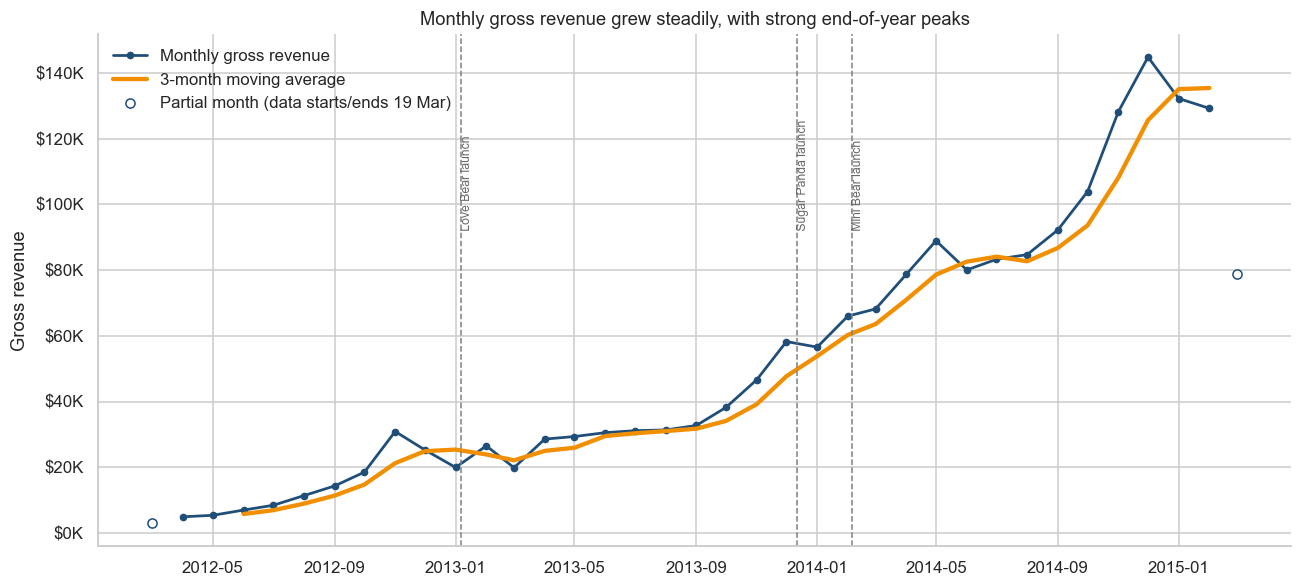

In [18]:
# Create a wide figure for the revenue trend
fig, ax = plt.subplots(figsize=(12, 5.5))
# Split the monthly table into complete and partial months
comp, part = monthly[monthly["complete"]], monthly[~monthly["complete"]]
# Draw monthly revenue (in thousands of dollars) for the complete months
ax.plot(comp["month"], comp["gross_revenue"] / 1000, color=PALETTE[0], marker="o", ms=4, lw=1.8, label="Monthly gross revenue")
# Draw the smoothed 3-month moving average
ax.plot(comp["month"], comp["revenue_ma3"] / 1000, color=PALETTE[2], lw=2.8, label="3-month moving average")
# Show the two partial months as hollow markers
ax.scatter(part["month"], part["gross_revenue"] / 1000, facecolor="white", edgecolor=PALETTE[0], zorder=5, label="Partial month (data starts/ends 19 Mar)")
# Mark each product launch after the first product with a dashed vertical line
for _, row in products.iloc[1:].iterrows():
    # Draw the vertical launch line
    ax.axvline(row["created_at"].normalize(), ls="--", color="grey", lw=1)
    # Label the line with the product name
    ax.text(row["created_at"].normalize(), ax.get_ylim()[1] * 0.6, f" {row['short_name']} launch", rotation=90, va="bottom", fontsize=8, color="dimgrey")
# Format the y-axis as thousands of dollars
ax.yaxis.set_major_formatter(lambda x, p: f"${x:,.0f}K")
# Add title and axis labels
ax.set(title="Monthly gross revenue grew steadily, with strong end-of-year peaks", xlabel="", ylabel="Gross revenue")
# Show the legend in the upper-left corner
ax.legend(loc="upper left", frameon=False)
# Save and show the figure
save_fig("fig01_monthly_revenue_trend")

**Findings - revenue over time**
- Gross revenue grew from **$129,274** (partial 2012, from 19 March) to **$393,248** in 2013 (+204%) and **$1,075,612** in 2014 (+174%). The business has earned **$1,938,510** in total at a 62.7% gross margin.
- The growth is steady rather than a one-off jump, and the best complete month was **December 2014** ($144,823).
- Revenue peaks every **November-December** (holiday season) and softens in January (down versus December in all three years), which signals clear **seasonality** (quantified in Task 3).
- Growth came from two sources at once: more traffic (sessions rose from 112,781 in 2013 to 233,422 in 2014) **and** a better conversion rate (4.1% in 2012 to 7.2% in 2014).
- Average order value rose from $49.99 to $63.80, helped by the cross-sell feature (see 2.3).

## 2.2 Which products generate the highest sales?

In [19]:
# Aggregate order items by product
prod = items.groupby("product_name").agg(
    units=("order_item_id", "count"), revenue=("price_usd", "sum"), cogs=("cogs_usd", "sum"),
    refunded_units=("is_refunded", "sum"), refunds=("refund_usd", "sum")).reset_index()
# Bring in the short name and launch date of each product
prod = prod.merge(products[["product_name", "short_name", "created_at"]].rename(columns={"created_at": "launch_date"}), on="product_name")
# Share of total revenue contributed by each product
prod["revenue_share_pct"] = prod["revenue"] / prod["revenue"].sum() * 100
# Gross profit and gross margin percentage per product
prod["gross_profit"] = prod["revenue"] - prod["cogs"]
# Gross margin as a percentage of revenue
prod["gross_margin_pct"] = prod["gross_profit"] / prod["revenue"] * 100
# Average selling price per unit
prod["avg_price"] = prod["revenue"] / prod["units"]
# Refund rate = refunded units / units sold
prod["refund_rate_pct"] = prod["refunded_units"] / prod["units"] * 100
# Profit after subtracting refunds
prod["net_profit"] = prod["gross_profit"] - prod["refunds"]
# Number of days each product has been on sale until the end of the data
prod["days_on_sale"] = (sessions["created_at"].max() - prod["launch_date"]).dt.days
# Revenue earned per day on sale (fair comparison between old and new products)
prod["revenue_per_day"] = prod["revenue"] / prod["days_on_sale"]
# Sort by revenue so the best seller comes first
prod = prod.sort_values("revenue", ascending=False).reset_index(drop=True)
# Display the product performance table
display(prod[["product_name", "launch_date", "units", "revenue", "revenue_share_pct", "avg_price", "gross_margin_pct", "net_profit", "revenue_per_day", "refund_rate_pct"]])

,product_name,launch_date,units,revenue,revenue_share_pct,avg_price,gross_margin_pct,net_profit,revenue_per_day,refund_rate_pct
0,The Original Mr. Fuzzy,2012-03-19 08:00:00,24226,"1,211,057.74",62.47,49.99,61.01,"677,055.37","1,107.00",5.11
1,The Forever Love Bear,2013-01-06 13:00:00,5796,"347,702.04",17.94,59.99,62.51,"209,611.29",434.08,2.23
2,The Birthday Sugar Panda,2013-12-12 09:00:00,4985,"229,260.15",11.83,45.99,68.49,"143,184.51",497.31,6.04
3,The Hudson River Mini bear,2014-02-05 10:00:00,5018,"150,489.82",7.76,29.99,68.36,"100,949.64",370.66,1.28


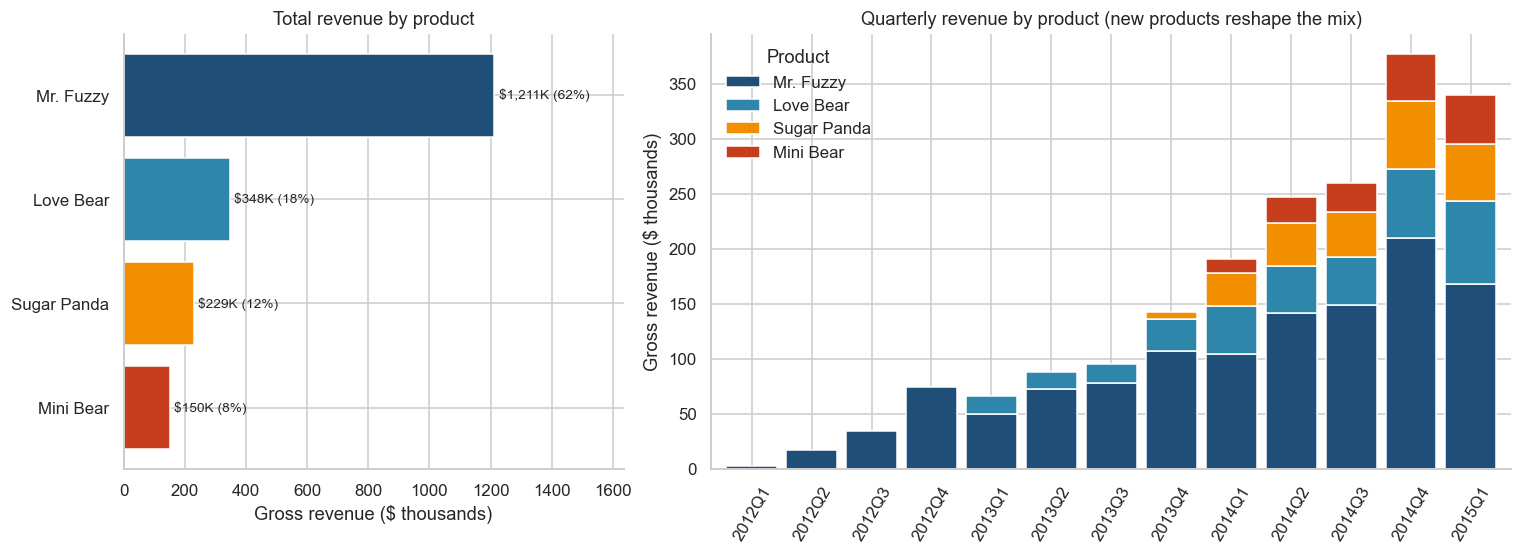

In [20]:
# Revenue per quarter and product (rows = quarter, columns = product), 0 before launch
prod_q = items.pivot_table(index="quarter", columns="short_name", values="price_usd", aggfunc="sum").fillna(0)
# Order the columns by launch date of the products
prod_q = prod_q[products["short_name"].tolist()]
# Create two side-by-side charts
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1, 1.6]})
# Left chart: total revenue by product as horizontal bars (best seller on top)
bars = axes[0].barh(prod["short_name"][::-1], prod["revenue"][::-1] / 1000, color=PALETTE[:4][::-1])
# Write the revenue and its share inside each bar label
for bar, (_, r) in zip(bars, prod.iloc[::-1].iterrows()):
    # Place the label just to the right of each bar
    axes[0].text(bar.get_width() + 15, bar.get_y() + bar.get_height() / 2, f"${r['revenue']/1000:,.0f}K ({r['revenue_share_pct']:.0f}%)", va="center", fontsize=9)
# Add a title and axis label to the left chart
axes[0].set(title="Total revenue by product", xlabel="Gross revenue ($ thousands)", xlim=(0, prod["revenue"].max() / 1000 * 1.35))
# Right chart: quarterly revenue stacked by product
prod_q.div(1000).plot(kind="bar", stacked=True, ax=axes[1], color=PALETTE[:4], width=0.85)
# Add a title and axis labels to the right chart
axes[1].set(title="Quarterly revenue by product (new products reshape the mix)", xlabel="", ylabel="Gross revenue ($ thousands)")
# Rotate the quarter labels for readability
axes[1].tick_params(axis="x", rotation=60)
# Place the legend with a clear title
axes[1].legend(title="Product", frameon=False)
# Save and show the figure
save_fig("fig02_revenue_by_product")

In [21]:
# Store the product headline numbers
top = prod.iloc[0]
# Share of revenue of the best seller in the first full quarter of 2013 versus the latest full quarter (2015Q1 is partial, so use 2014Q4)
share_mix = prod_q.div(prod_q.sum(axis=1), axis=0) * 100
# Save the key figures
M.update(top_product=top["product_name"], top_share=top["revenue_share_pct"], top_rev=top["revenue"], top_units=top["units"],
         fuzzy_share_2012q4=share_mix.loc["2012Q4", "Mr. Fuzzy"], fuzzy_share_2014q4=share_mix.loc["2014Q4", "Mr. Fuzzy"],
         lovebear_rev=prod.set_index("short_name").loc["Love Bear", "revenue"], panda_rev=prod.set_index("short_name").loc["Sugar Panda", "revenue"],
         mini_rev=prod.set_index("short_name").loc["Mini Bear", "revenue"], mini_margin=prod.set_index("short_name").loc["Mini Bear", "gross_margin_pct"],
         lovebear_margin=prod.set_index("short_name").loc["Love Bear", "gross_margin_pct"], fuzzy_margin=prod.set_index("short_name").loc["Mr. Fuzzy", "gross_margin_pct"],
         panda_margin=prod.set_index("short_name").loc["Sugar Panda", "gross_margin_pct"])
# Display the product mix (% of quarterly revenue) for the last complete quarters
display(share_mix.round(1).tail(6))

short_name,Mr. Fuzzy,Love Bear,Sugar Panda,Mini Bear
quarter,,,,
2013Q4,74.90,20.60,4.50,0.00
2014Q1,55.00,22.90,15.80,6.40
2014Q2,57.30,17.10,15.90,9.80
2014Q3,57.10,16.90,15.70,10.30
2014Q4,55.80,16.70,16.30,11.30
2015Q1,49.50,22.20,15.10,13.20


**Findings - best-selling products**
- **The Original Mr. Fuzzy** is the clear leader: $1,211,058 in revenue (62% of the total) and 24,226 units. It is also the oldest product, on sale for the full three years.
- The newer products have grown the catalogue: **The Forever Love Bear** ($347,702), **The Birthday Sugar Panda** ($229,260) and **The Hudson River Mini bear** ($150,490). They launched later, so their totals understate their strength (the table shows revenue per day on sale).
- Mr. Fuzzy was the only product in 2012 (100% of revenue); by 2014Q4 its share was 56%, so the business is **less dependent on a single product** than it used to be.
- Gross margins are healthy for every product (Mr. Fuzzy 61%, Love Bear 63%, Sugar Panda 68%, Mini Bear 68%), and the two newest products, Sugar Panda and Mini Bear, carry the best margins. The Mini Bear is also the cheapest product, which makes it an ideal low-friction add-on (see 2.3).

## 2.3 What are the patterns in customer purchasing behaviour?
We look at (a) basket size and cross-selling, (b) when customers buy (weekday and hour), and (c) repeat buying.

In [22]:
# Date of the first order that contained two items (introduction of the cross-sell feature)
first_bundle = orders.loc[orders["is_bundle"] == 1, "created_at"].min()
# Print the cross-sell launch date
print("First 2-item order:", first_bundle.date())
# Share of 2-item orders and average order value by year
basket_year = orders.groupby("year").agg(orders=("order_id", "count"), bundle_share_pct=("is_bundle", lambda s: s.mean() * 100), aov=("price_usd", "mean"), items_per_order=("items_purchased", "mean"))
# Display the yearly basket table
display(basket_year)
# Average order value of one-item versus two-item orders after cross-selling started
aov_by_size = orders[orders["created_at"] >= first_bundle].groupby("items_purchased")["price_usd"].agg(orders="count", avg_order_value="mean")
# Display the basket-size comparison
display(aov_by_size)

First 2-item order: 2013-09-25


,orders,bundle_share_pct,aov,items_per_order
year,,,,
2012,2586,0.00,49.99,1.00
2013,7447,2.23,52.81,1.02
2014,16860,33.93,63.80,1.34
2015,5420,33.67,62.80,1.34


,orders,avg_order_value
items_purchased,,
1,17302,50.71
2,7712,89.25


In [23]:
# Map product ids to short product names for readability
id_to_name = products.set_index("product_id")["short_name"]
# Cross-sell attach rate by primary product, using the period after cross-sell launched
post = orders[orders["created_at"] >= first_bundle].copy()
# Translate the primary product id into a name
post["primary_product"] = post["primary_product_id"].map(id_to_name)
# Orders and bundle rate by primary product
attach = post.groupby("primary_product").agg(orders=("order_id", "count"), cross_sell_rate_pct=("is_bundle", lambda s: s.mean() * 100)).sort_values("cross_sell_rate_pct", ascending=False)
# Which products are chosen as the second (cross-sell) item
cross_items = items[items["item_role"] == "Cross-sell item"].groupby("short_name").size().rename("times_added_as_cross_sell").sort_values(ascending=False)
# Display both tables side by side as one result
display(attach)
# Display the cross-sell item popularity
display(cross_items)

,orders,cross_sell_rate_pct
primary_product,,
Sugar Panda,3068,33.54
Mr. Fuzzy,17365,33.15
Love Bear,4000,21.98
Mini Bear,581,8.09


short_name
Mini Bear      4437
Sugar Panda    1917
Love Bear       993
Mr. Fuzzy       365
Name: times_added_as_cross_sell, dtype: int64

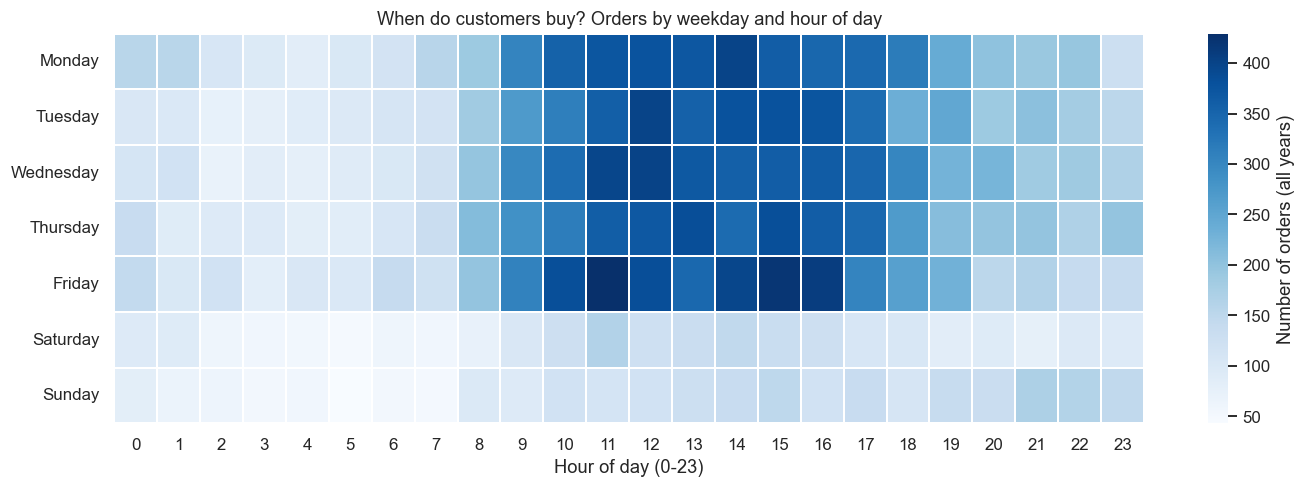

In [24]:
# Count orders for every weekday and hour combination
heat = orders.pivot_table(index="weekday", columns="hour", values="order_id", aggfunc="count").fillna(0)
# Put the weekdays in calendar order
heat = heat.reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
# Draw the heatmap
fig, ax = plt.subplots(figsize=(13, 4.6))
# Use a sequential colour palette; darker = more orders
sns.heatmap(heat, cmap="Blues", ax=ax, cbar_kws={"label": "Number of orders (all years)"}, linewidths=0.3)
# Add title and axis labels
ax.set(title="When do customers buy? Orders by weekday and hour of day", xlabel="Hour of day (0-23)", ylabel="")
# Save and show the figure
save_fig("fig03_orders_weekday_hour_heatmap")

In [25]:
# Average orders per calendar day for weekdays versus weekend days (complete days only)
daily_orders = orders[(orders["date"] >= FIRST_FULL_DAY) & (orders["date"] <= LAST_FULL_DAY)].groupby("date").size()
# Add the weekday number to each day
dow = daily_orders.groupby(daily_orders.index.dayofweek).mean()
# Average orders on a weekday (Mon-Fri) and a weekend day (Sat-Sun)
wk_avg, we_avg = dow.loc[0:4].mean(), dow.loc[5:6].mean()
# Share of all orders placed between 09:00 and 17:59
office_share = orders["hour"].between(9, 17).mean()
# Share of all orders placed from 00:00 to 06:59 (night)
night_share = orders["hour"].between(0, 6).mean()
# Print the time-pattern results
print(f"Avg orders per weekday: {wk_avg:.1f} | per weekend day: {we_avg:.1f} | weekend is {we_avg / wk_avg * 100:.0f}% of a weekday")
# Print the share of orders in office hours and at night
print(f"Orders between 09:00-17:59: {pct(office_share)} | between 00:00-06:59: {pct(night_share)}")
# Store the results
M.update(wk_avg=wk_avg, we_avg=we_avg, office_share=office_share, night_share=night_share)

Avg orders per weekday: 35.2 | per weekend day: 15.7 | weekend is 45% of a weekday
Orders between 09:00-17:59: 57.0% | between 00:00-06:59: 13.8%


In [26]:
# Number of orders placed by each customer (user)
orders_per_user = orders.groupby("user_id").size()
# Number of customers who bought at least twice
repeat_buyers = int((orders_per_user > 1).sum())
# Repeat-buyer share among all customers who ever ordered
repeat_buyer_rate = repeat_buyers / len(orders_per_user)
# Sort orders per customer chronologically
o_sorted = orders.sort_values(["user_id", "created_at"]).copy()
# Time of the previous order of the same customer
o_sorted["previous_order"] = o_sorted.groupby("user_id")["created_at"].shift()
# Days between consecutive orders of the same customer
gap_days = (o_sorted["created_at"] - o_sorted["previous_order"]).dt.days.dropna()
# Share of orders that were placed during a returning-visitor session
orders_on_return_visit = (orders["visitor_type"] == "Returning").mean()
# Print the repeat-purchase statistics
print(f"Customers who ordered: {len(orders_per_user):,} | repeat buyers (2+ orders): {repeat_buyers:,} ({pct(repeat_buyer_rate)})")
# Print timing and return-visit statistics
print(f"Median days between two orders of the same customer: {gap_days.median():.0f}")
# Print how many orders are placed on a return visit
print(f"Orders placed on a return visit (not the first session): {pct(orders_on_return_visit)}")
# Store the results
M.update(customers=len(orders_per_user), repeat_buyers=repeat_buyers, repeat_buyer_rate=repeat_buyer_rate, repeat_gap_median=gap_days.median(), orders_on_return_visit=orders_on_return_visit)

Customers who ordered: 31,696 | repeat buyers (2+ orders): 591 (1.9%)
Median days between two orders of the same customer: 29
Orders placed on a return visit (not the first session): 19.0%


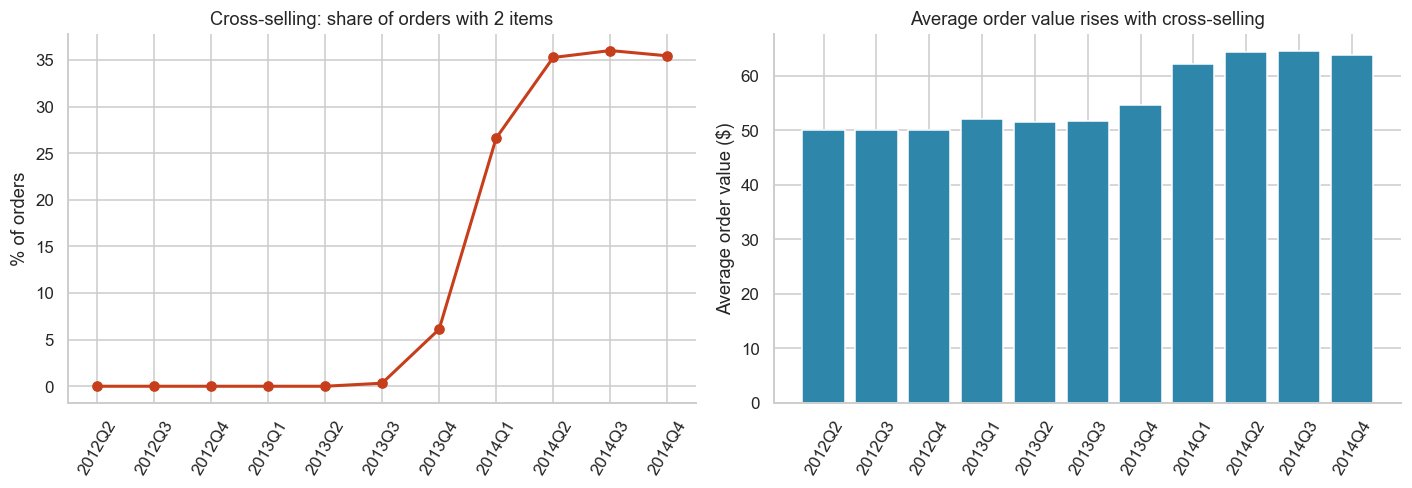

In [27]:
# Quarterly share of 2-item orders and quarterly average order value (complete quarters only)
bq = orders.groupby("quarter").agg(bundle_share=("is_bundle", "mean"), aov=("price_usd", "mean"))
# Remove the two partial quarters
bq = bq.loc[qtr.loc[qtr["complete"], "quarter"]]
# Create two charts side by side
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
# Left chart: share of orders containing two items
axes[0].plot(bq.index, bq["bundle_share"] * 100, marker="o", color=PALETTE[3], lw=2)
# Add the title and labels of the left chart
axes[0].set(title="Cross-selling: share of orders with 2 items", ylabel="% of orders", xlabel="")
# Right chart: average order value
axes[1].bar(bq.index, bq["aov"], color=PALETTE[1])
# Add the title and labels of the right chart
axes[1].set(title="Average order value rises with cross-selling", ylabel="Average order value ($)", xlabel="")
# Rotate the quarter labels on both charts
for ax in axes:
    # Rotate the labels for readability
    ax.tick_params(axis="x", rotation=60)
# Save and show the figure
save_fig("fig04_cross_sell_and_aov")

In [28]:
# Store the basket results used in the narrative
M.update(aov_single=aov_by_size.loc[1, "avg_order_value"], aov_double=aov_by_size.loc[2, "avg_order_value"], first_bundle=first_bundle, bundle_share_2014=basket_year.loc[2014, "bundle_share_pct"] / 100, aov_2013=basket_year.loc[2013, "aov"],
         attach_best=attach.index[0], attach_best_rate=attach.iloc[0]["cross_sell_rate_pct"] / 100,
         attach_worst=attach.index[-1], attach_worst_rate=attach.iloc[-1]["cross_sell_rate_pct"] / 100,
         cross_top=cross_items.index[0], cross_top_n=int(cross_items.iloc[0]))

**Findings - customer purchasing behaviour**
- **Cross-selling works.** A second-item option appeared on **25 Sep 2013**. By 2014, **34%** of orders contained two items, lifting the average order value from $49.99 (2012) to $63.80 (2014): a two-item order is worth $89.25 on average versus $50.71 for a single item. The best cross-sell host is Sugar Panda (34% of its orders add a second item) and the most added second item is Mini Bear.
- **Customers shop during the working day.** 57% of orders are placed between 09:00 and 17:59, only 14% overnight. A weekday brings about 35 orders against 16 on a weekend day.
- **Buyers rarely come back to buy again.** Only 1.9% of customers (591 of 31,696) placed a second order; those who did waited a median of 29 days.
- **But many buyers need more than one visit.** 19% of orders are placed during a *returning-visitor* session, which means the first visit was research and the purchase happened later.

## 2.4 Which marketing channels attract the most website sessions?
Channels were derived in Section 1.5 from the UTM tags and the referrer.

In [29]:
# Aggregate sessions, orders and revenue by marketing channel
channel = sessions.groupby("channel").agg(
    sessions=("website_session_id", "count"), orders=("converted", "sum"), revenue=("revenue_usd", "sum"),
    first_session=("created_at", "min")).reset_index()
# Share of all sessions coming from each channel
channel["share_of_sessions_pct"] = channel["sessions"] / channel["sessions"].sum() * 100
# Conversion rate = orders / sessions
channel["conversion_rate_pct"] = channel["orders"] / channel["sessions"] * 100
# Revenue earned per session (a measure of traffic quality)
channel["revenue_per_session"] = channel["revenue"] / channel["sessions"]
# Share of all revenue coming from each channel
channel["share_of_revenue_pct"] = channel["revenue"] / channel["revenue"].sum() * 100
# Sort by number of sessions
channel = channel.sort_values("sessions", ascending=False).reset_index(drop=True)
# Display the channel table
display(channel)

,channel,sessions,orders,revenue,first_session,share_of_sessions_pct,conversion_rate_pct,revenue_per_session,share_of_revenue_pct
0,Google nonbrand,282706,18822,"1,124,414.21",2012-03-19 08:04:00,59.79,6.66,3.98,58.00
1,Bing nonbrand,54909,3818,"225,563.48",2012-08-19 01:43:00,11.61,6.95,4.11,11.64
2,Organic search,43411,3262,"196,809.19",2012-03-26 20:32:00,9.18,7.51,4.53,10.15
3,Paid brand search,41243,3212,"194,839.70",2012-03-25 23:06:00,8.72,7.79,4.72,10.05
4,Direct,39917,2856,"174,623.84",2012-03-25 07:24:00,8.44,7.15,4.37,9.01
5,Social (Socialbook),10685,343,"22,259.33",2014-01-12 00:38:00,2.26,3.21,2.08,1.15


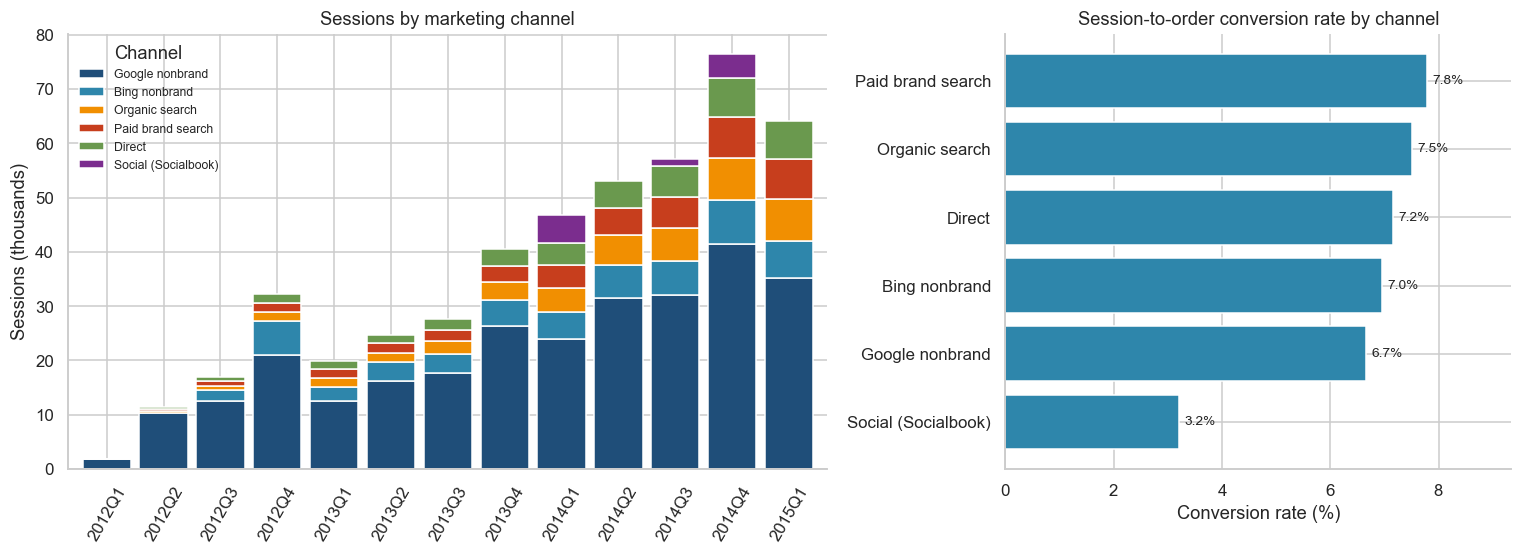

In [30]:
# Quarterly sessions by channel (rows = quarter, columns = channel)
ch_q = sessions.pivot_table(index="quarter", columns="channel", values="website_session_id", aggfunc="count").fillna(0)
# Order the columns from the largest to the smallest channel
ch_q = ch_q[channel["channel"].tolist()]
# Create two charts side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.5, 1]})
# Left chart: stacked bars of quarterly sessions by channel
ch_q.div(1000).plot(kind="bar", stacked=True, ax=axes[0], color=PALETTE[:6], width=0.85)
# Add title and axis labels to the left chart
axes[0].set(title="Sessions by marketing channel", xlabel="", ylabel="Sessions (thousands)")
# Rotate the quarter labels for readability
axes[0].tick_params(axis="x", rotation=60)
# Move the legend outside to keep the bars readable
axes[0].legend(title="Channel", frameon=False, fontsize=8)
# Right chart: conversion rate per channel as horizontal bars
sorted_ch = channel.sort_values("conversion_rate_pct")
# Draw the bars
axes[1].barh(sorted_ch["channel"], sorted_ch["conversion_rate_pct"], color=PALETTE[1])
# Write the percentage at the end of each bar
for i, v in enumerate(sorted_ch["conversion_rate_pct"]):
    # Place the text label slightly to the right of the bar end
    axes[1].text(v + 0.1, i, f"{v:.1f}%", va="center", fontsize=9)
# Add title and axis label to the right chart
axes[1].set(title="Session-to-order conversion rate by channel", xlabel="Conversion rate (%)", xlim=(0, sorted_ch["conversion_rate_pct"].max() * 1.2))
# Save and show the figure
save_fig("fig05_channels_sessions_and_conversion")

In [31]:
# Look at the paid ad variants (utm_content) to see which creatives and sources perform
ads = sessions[sessions["utm_content"] != "none"].groupby(["utm_source", "utm_campaign", "utm_content"]).agg(
    sessions=("website_session_id", "count"), orders=("converted", "sum"), first_seen=("created_at", "min"), last_seen=("created_at", "max")).reset_index()
# Conversion rate of each ad variant
ads["conversion_rate_pct"] = ads["orders"] / ads["sessions"] * 100
# Display the ad variants sorted by traffic
display(ads.sort_values("sessions", ascending=False))

,utm_source,utm_campaign,utm_content,sessions,orders,first_seen,last_seen,conversion_rate_pct
3,gsearch,nonbrand,g_ad_1,282706,18822,2012-03-19 08:04:00,2015-03-19 07:56:00,6.66
1,bsearch,nonbrand,b_ad_1,54909,3818,2012-08-19 01:43:00,2015-03-19 07:54:00,6.95
2,gsearch,brand,g_ad_2,33329,2511,2012-03-25 23:06:00,2015-03-19 07:49:00,7.53
0,bsearch,brand,b_ad_2,7914,701,2012-03-27 22:54:00,2015-03-19 06:28:00,8.86
4,socialbook,desktop_targeted,social_ad_2,5590,288,2014-08-17 04:55:00,2014-12-27 23:50:00,5.15
5,socialbook,pilot,social_ad_1,5095,55,2014-01-12 00:38:00,2014-03-15 23:47:00,1.08


In [32]:
# Index the channel table by name for easy lookup
ch = channel.set_index("channel")
# Store the channel numbers used in the narrative
M.update(g_nb_sessions=ch.loc["Google nonbrand", "sessions"], g_nb_share=ch.loc["Google nonbrand", "share_of_sessions_pct"] / 100,
         g_nb_rev_share=ch.loc["Google nonbrand", "share_of_revenue_pct"] / 100, g_nb_cvr=ch.loc["Google nonbrand", "conversion_rate_pct"],
         b_nb_cvr=ch.loc["Bing nonbrand", "conversion_rate_pct"], brand_cvr=ch.loc["Paid brand search", "conversion_rate_pct"],
         org_cvr=ch.loc["Organic search", "conversion_rate_pct"], direct_cvr=ch.loc["Direct", "conversion_rate_pct"],
         social_cvr=ch.loc["Social (Socialbook)", "conversion_rate_pct"], social_sessions=ch.loc["Social (Socialbook)", "sessions"],
         social_rps=ch.loc["Social (Socialbook)", "revenue_per_session"], g_nb_rps=ch.loc["Google nonbrand", "revenue_per_session"],
         brand_rps=ch.loc["Paid brand search", "revenue_per_session"], social_first=ch.loc["Social (Socialbook)", "first_session"],
         unpaid_share=(ch.loc[["Direct", "Organic search", "Paid brand search"], "sessions"].sum() / ch["sessions"].sum()))
# Sessions per year and channel to see which channels are growing fastest
ch_year = sessions.pivot_table(index="year", columns="channel", values="website_session_id", aggfunc="count")
# Brand-aware channels = direct + organic + paid brand search
aware_cols = ["Direct", "Organic search", "Paid brand search"]
# Share of yearly sessions that comes from brand-aware channels
aware_share = ch_year[aware_cols].sum(axis=1) / ch_year.sum(axis=1)
# Growth multiple between 2012 and 2014 for brand-aware sessions and for Google non-brand sessions
M.update(aware_share_2012=aware_share[2012], aware_share_2014=aware_share[2014],
         aware_growth=ch_year.loc[2014, aware_cols].sum() / ch_year.loc[2012, aware_cols].sum(),
         gnb_growth=ch_year.loc[2014, "Google nonbrand"] / ch_year.loc[2012, "Google nonbrand"])
# Display the yearly sessions by channel
display(ch_year)

channel,Bing nonbrand,Direct,Google nonbrand,Organic search,Paid brand search,Social (Socialbook)
year,,,,,,
2012,"8,269.00","2,780.00","45,604.00","2,973.00","2,844.00",NaN
2013,"14,436.00","8,136.00","72,806.00","8,914.00","8,489.00",NaN
2014,"25,367.00","21,877.00","129,154.00","23,732.00","22,607.00","10,685.00"
2015,"6,837.00","7,124.00","35,142.00","7,792.00","7,303.00",NaN


**Findings - marketing channels**
- **Google non-brand search is the engine of traffic:** 282,706 sessions, 60% of all visits and 58% of revenue. Bing non-brand is a distant second.
- **Quality differs from quantity.** Visitors who already know the brand convert best (paid brand search 7.8%, organic 7.5%, direct 7.2%) while generic non-brand search converts at 6.7% (Google) and 7.0% (Bing).
- **Socialbook is the weakest channel:** it appeared in Jan 2014, delivered 10,685 sessions but only 3.2% conversion and $2.08 revenue per session (vs. $3.98 for Google non-brand).
- **Brand-aware traffic is the fastest-growing source.** Direct, organic and paid-brand sessions grew 7.9x between 2012 and 2014 (Google non-brand: 2.8x), lifting their share of all sessions from 14% to 29%. These visitors convert best and cost the least to acquire.

## 2.5 How does website traffic differ between mobile and desktop users?

In [33]:
# Aggregate sessions, orders and revenue by device type
device = sessions.groupby("device_type").agg(sessions=("website_session_id", "count"), orders=("converted", "sum"), revenue=("revenue_usd", "sum")).reset_index()
# Share of sessions by device
device["share_of_sessions_pct"] = device["sessions"] / device["sessions"].sum() * 100
# Share of orders by device
device["share_of_orders_pct"] = device["orders"] / device["orders"].sum() * 100
# Share of revenue by device
device["share_of_revenue_pct"] = device["revenue"] / device["revenue"].sum() * 100
# Conversion rate by device
device["conversion_rate_pct"] = device["orders"] / device["sessions"] * 100
# Revenue per session by device
device["revenue_per_session"] = device["revenue"] / device["sessions"]
# Average order value by device
device["aov"] = device["revenue"] / device["orders"]
# Display the device comparison
display(device)

,device_type,sessions,orders,revenue,share_of_sessions_pct,share_of_orders_pct,share_of_revenue_pct,conversion_rate_pct,revenue_per_session,aov
0,Desktop,327027,27805,"1,665,757.84",69.16,86.05,85.93,8.50,5.09,59.91
1,Mobile,145844,4508,"272,751.91",30.84,13.95,14.07,3.09,1.87,60.50


In [34]:
# Conversion rate by quarter and device, in percent
dev_q = sessions.groupby(["quarter", "device_type"])["converted"].mean().unstack() * 100
# Share of mobile sessions by quarter, in percent
mobile_share_q = sessions.groupby("quarter")["device_type"].apply(lambda s: (s == "Mobile").mean() * 100)
# Device mix inside each channel (row percentages)
dev_channel = pd.crosstab(sessions["channel"], sessions["device_type"], normalize="index") * 100
# Display the device mix by channel
display(dev_channel)
# Conversion rate by year and device, in percent
dev_year = sessions.groupby(["year", "device_type"])["converted"].mean().unstack() * 100
# Display the yearly device conversion rates
display(dev_year)

device_type,Desktop,Mobile
channel,,
Bing nonbrand,86.32,13.68
Direct,58.33,41.67
Google nonbrand,69.03,30.97
Organic search,65.17,34.83
Paid brand search,64.95,35.05
Social (Socialbook),57.20,42.80


device_type,Desktop,Mobile
year,,
2012,5.05,1.47
2013,8.02,3.12
2014,9.18,3.31
2015,10.59,3.50


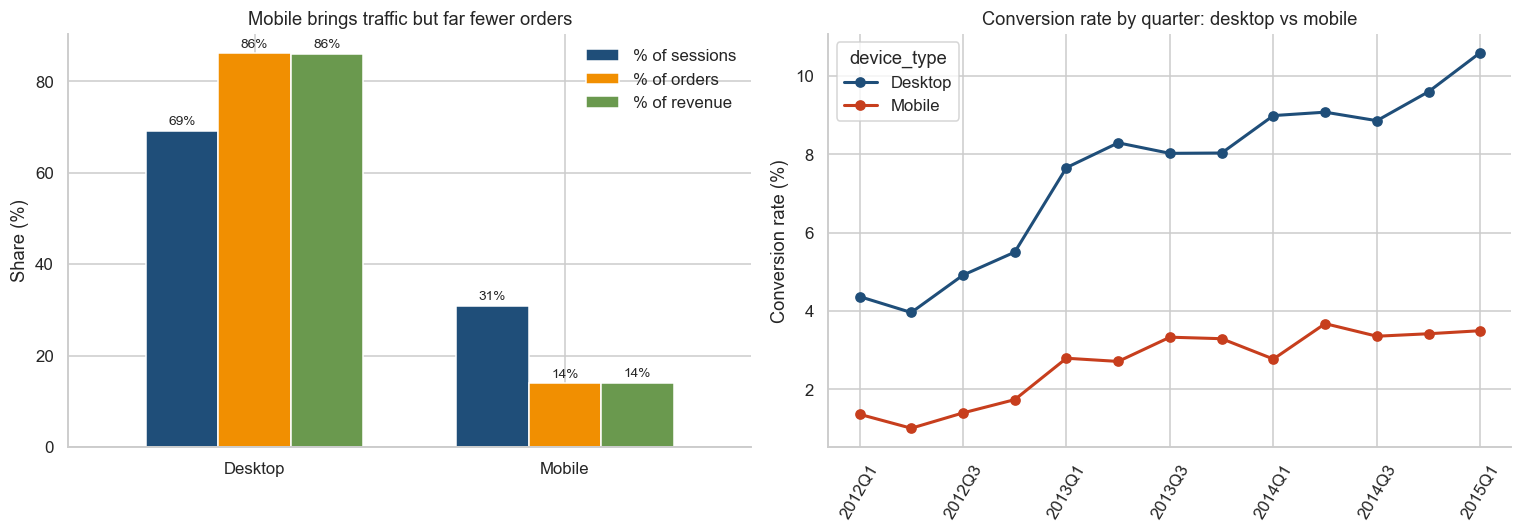

In [35]:
# Create two charts side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# Prepare data for the grouped bars: share of sessions, orders and revenue per device
share_cols = ["share_of_sessions_pct", "share_of_orders_pct", "share_of_revenue_pct"]
# Draw grouped bars for each device
device.set_index("device_type")[share_cols].plot(kind="bar", ax=axes[0], color=[PALETTE[0], PALETTE[2], PALETTE[4]], width=0.7)
# Write the percentage on top of each bar
for container in axes[0].containers:
    # Add rounded labels to every bar in the group
    axes[0].bar_label(container, fmt="%.0f%%", fontsize=9, padding=2)
# Add title and axis labels to the left chart
axes[0].set(title="Mobile brings traffic but far fewer orders", xlabel="", ylabel="Share (%)")
# Keep the device names horizontal
axes[0].tick_params(axis="x", rotation=0)
# Replace the long column names with readable legend labels
axes[0].legend(["% of sessions", "% of orders", "% of revenue"], frameon=False)
# Right chart: conversion rate over time for each device
dev_q.plot(ax=axes[1], marker="o", color=[PALETTE[0], PALETTE[3]], lw=2)
# Add title and axis labels to the right chart
axes[1].set(title="Conversion rate by quarter: desktop vs mobile", xlabel="", ylabel="Conversion rate (%)")
# Rotate the quarter labels
axes[1].tick_params(axis="x", rotation=60)
# Save and show the figure
save_fig("fig06_mobile_vs_desktop")

In [36]:
# Index the device table for lookup
dv = device.set_index("device_type")
# Store the device numbers used in the narrative
M.update(mobile_share=dv.loc["Mobile", "share_of_sessions_pct"] / 100, mobile_order_share=dv.loc["Mobile", "share_of_orders_pct"] / 100,
         mobile_cvr=dv.loc["Mobile", "conversion_rate_pct"], desktop_cvr=dv.loc["Desktop", "conversion_rate_pct"],
         cvr_ratio=dv.loc["Desktop", "conversion_rate_pct"] / dv.loc["Mobile", "conversion_rate_pct"],
         mobile_rps=dv.loc["Mobile", "revenue_per_session"], desktop_rps=dv.loc["Desktop", "revenue_per_session"],
         mobile_aov=dv.loc["Mobile", "aov"], desktop_aov=dv.loc["Desktop", "aov"],
         mobile_cvr_2012=dev_year.loc[2012, "Mobile"], mobile_cvr_2013=dev_year.loc[2013, "Mobile"], mobile_cvr_2014=dev_year.loc[2014, "Mobile"], mobile_cvr_2015=dev_year.loc[2015, "Mobile"],
         desktop_cvr_2012=dev_year.loc[2012, "Desktop"], desktop_cvr_2013=dev_year.loc[2013, "Desktop"], desktop_cvr_2014=dev_year.loc[2014, "Desktop"], desktop_cvr_2015=dev_year.loc[2015, "Desktop"])

**Findings - mobile vs desktop**
- Mobile accounts for **31%** of all sessions but only **14%** of orders and revenue.
- Desktop sessions convert at **8.5%** versus **3.1%** on mobile, a **2.8x gap**. Revenue per session is $5.09 on desktop against $1.87 on mobile, while order values are similar ($59.91 vs $60.50), so the problem is *getting* mobile visitors to buy, not how much they spend.
- The gap is **persistent**. Mobile conversion more than doubled from 1.5% (2012) to 3.1% (2013) but then plateaued (3.3% in 2014, 3.5% in early 2015), while desktop kept climbing (8.0% in 2013, 9.2% in 2014, 10.6% in early 2015). Mobile has therefore been left behind by whatever is lifting desktop results.

## 2.6 What proportion of website sessions result in orders?

In [37]:
# Overall session-to-order conversion rate
overall_cvr = sessions["converted"].mean()
# Print the overall conversion rate with the underlying counts
print(f"Overall: {sessions['converted'].sum():,} orders from {len(sessions):,} sessions = {pct(overall_cvr, 2)} conversion rate")
# Conversion rate by quarter for the trend chart
cvr_q = sessions.groupby("quarter")["converted"].mean() * 100
# Store the overall figure
M.update(overall_cvr=overall_cvr, cvr_q1_2013=cvr_q["2013Q1"], cvr_q4_2014=cvr_q["2014Q4"])
# Display the yearly conversion table created earlier
display(yearly[["sessions", "orders", "conversion_rate_pct"]])

Overall: 32,313 orders from 472,871 sessions = 6.83% conversion rate


,sessions,orders,conversion_rate_pct
year,,,
2012,62470,2586,4.14
2013,112781,7447,6.60
2014,233422,16860,7.22
2015,64198,5420,8.44


### Conversion funnel (page level)
We now follow visitors page by page. **This part uses only the 89.2% of sessions whose pageviews are fully present** (see Section 1.3).

In [38]:
# Keep only the sessions whose pageviews are complete (before the truncation point)
pv = pageviews[pageviews["website_session_id"] < PV_MAX_SESSION].sort_values("website_pageview_id").copy()
# Map every URL to a stage of the purchase funnel
STEP_MAP = {
    "/home": "Landing page", "/lander-1": "Landing page", "/lander-2": "Landing page", "/lander-3": "Landing page",
    "/lander-4": "Landing page", "/lander-5": "Landing page", "/products": "Products page",
    "/the-original-mr-fuzzy": "Product detail page", "/the-forever-love-bear": "Product detail page",
    "/the-birthday-sugar-panda": "Product detail page", "/the-hudson-river-mini-bear": "Product detail page",
    "/cart": "Cart", "/shipping": "Shipping", "/billing": "Billing", "/billing-2": "Billing",
    "/thank-you-for-your-order": "Order placed",
}
# Apply the mapping to every pageview
pv["step"] = pv["pageview_url"].map(STEP_MAP)
# Check that every URL was mapped to a funnel step
print("Unmapped pageviews:", int(pv["step"].isna().sum()))
# Order of the funnel stages from first to last
FUNNEL_ORDER = ["Landing page", "Products page", "Product detail page", "Cart", "Shipping", "Billing", "Order placed"]
# Count the distinct sessions that reached each stage
reach = pv.drop_duplicates(["website_session_id", "step"]).groupby("step")["website_session_id"].nunique().reindex(FUNNEL_ORDER)
# Build the funnel table
funnel = pd.DataFrame({"sessions": reach})
# Percentage of the previous stage that continued to this stage
funnel["pct_of_previous_step"] = funnel["sessions"] / funnel["sessions"].shift() * 100
# Percentage of all landing sessions that reached this stage
funnel["pct_of_all_sessions"] = funnel["sessions"] / funnel["sessions"].iloc[0] * 100
# Percentage lost between the previous stage and this one
funnel["drop_off_pct"] = 100 - funnel["pct_of_previous_step"]
# Display the funnel table
display(funnel)

Unmapped pageviews: 0


,sessions,pct_of_previous_step,pct_of_all_sessions,drop_off_pct
step,,,,
Landing page,421955,NaN,100.00,NaN
Products page,230534,54.63,54.63,45.37
Product detail page,184073,79.85,43.62,20.15
Cart,82603,44.88,19.58,55.12
Shipping,56124,67.94,13.30,32.06
Billing,45313,80.74,10.74,19.26
Order placed,27972,61.73,6.63,38.27


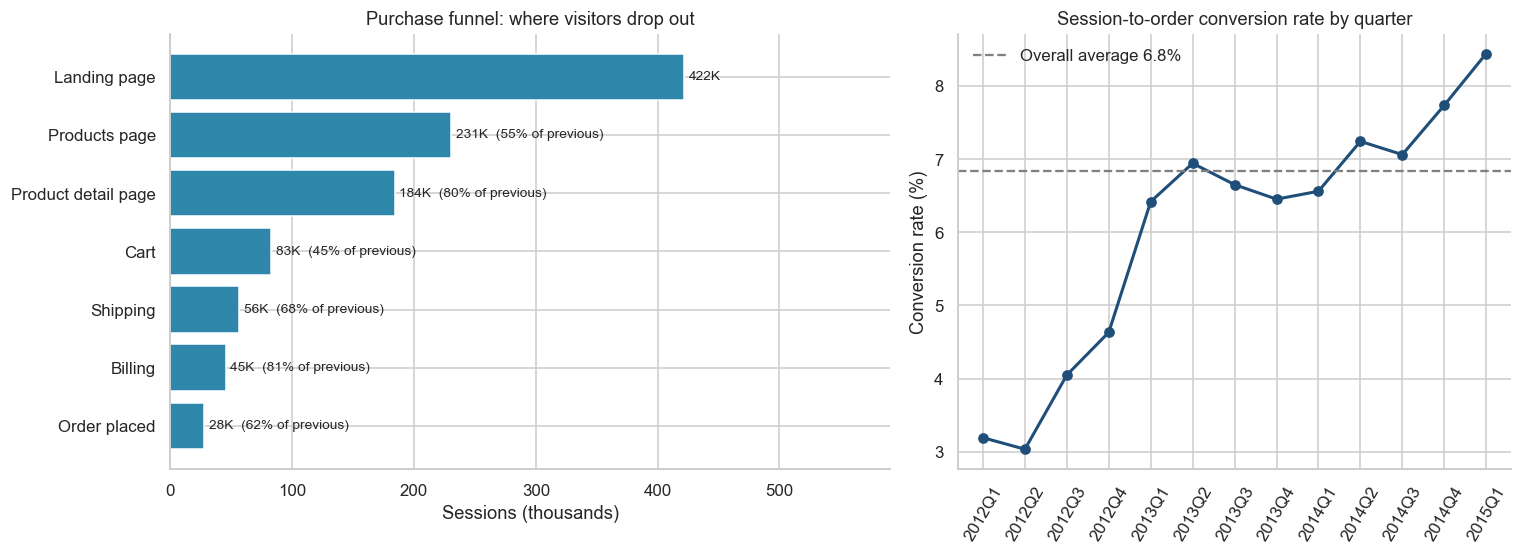

In [39]:
# Create two charts side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.3, 1]})
# Left chart: horizontal funnel bars (first stage on top)
axes[0].barh(funnel.index[::-1], funnel["sessions"][::-1] / 1000, color=PALETTE[1])
# Annotate every bar with its count and the share retained from the previous step
for i, (name, r) in enumerate(funnel.iloc[::-1].iterrows()):
    # Build the label text (the first stage has no previous step)
    label = f"{r['sessions']/1000:,.0f}K" + ("" if np.isnan(r["pct_of_previous_step"]) else f"  ({r['pct_of_previous_step']:.0f}% of previous)")
    # Place the label to the right of the bar
    axes[0].text(r["sessions"] / 1000 + 4, i, label, va="center", fontsize=9)
# Add title and axis labels to the left chart
axes[0].set(title="Purchase funnel: where visitors drop out", xlabel="Sessions (thousands)", xlim=(0, funnel["sessions"].max() / 1000 * 1.4))
# Right chart: conversion rate by quarter
axes[1].plot(cvr_q.index, cvr_q.values, marker="o", color=PALETTE[0], lw=2)
# Add a dashed line for the overall average conversion rate
axes[1].axhline(overall_cvr * 100, ls="--", color="grey", label=f"Overall average {overall_cvr*100:.1f}%")
# Add title and axis labels to the right chart
axes[1].set(title="Session-to-order conversion rate by quarter", xlabel="", ylabel="Conversion rate (%)")
# Rotate the quarter labels
axes[1].tick_params(axis="x", rotation=60)
# Show the legend
axes[1].legend(frameon=False)
# Save and show the figure
save_fig("fig07_conversion_funnel_and_trend")

In [40]:
# First page of every session = its landing page
first_pv = pv.drop_duplicates("website_session_id")[["website_session_id", "pageview_url", "created_at"]].rename(columns={"pageview_url": "landing_page", "created_at": "landing_time"})
# Number of pages viewed in every session
pages_per_session = pv.groupby("website_session_id").size().rename("pages_viewed")
# Combine landing page, pages viewed, device, channel and the conversion flag
landing = first_pv.merge(pages_per_session, on="website_session_id").merge(sessions[["website_session_id", "converted", "device_type", "channel"]], on="website_session_id")
# A session "bounced" if it viewed only one page
landing["bounced"] = (landing["pages_viewed"] == 1).astype(int)
# Summarise performance per landing page over ALL traffic
landing_all = landing.groupby("landing_page").agg(sessions=("website_session_id", "count"), mobile_share_pct=("device_type", lambda s: (s == "Mobile").mean() * 100),
    bounce_rate_pct=("bounced", lambda s: s.mean() * 100), conversion_rate_pct=("converted", lambda s: s.mean() * 100), first_used=("landing_time", "min"), last_used=("landing_time", "max")).reset_index()
# Keep landing pages with a meaningful number of sessions and order them by first use
landing_all = landing_all[landing_all["sessions"] >= 500].sort_values("first_used")
# Display the overall landing page table (note the very different mobile shares)
display(landing_all)

,landing_page,sessions,mobile_share_pct,bounce_rate_pct,conversion_rate_pct,first_used,last_used
0,/home,119992,36.55,41.99,6.89,2012-03-19 08:04:00,2015-01-16 18:53:00
1,/lander-1,47574,21.26,53.24,4.53,2012-06-19 00:35:00,2013-03-10 23:10:00
2,/lander-2,131170,4.89,45.17,7.72,2013-01-14 00:28:00,2014-12-27 23:50:00
3,/lander-3,69969,100.00,50.53,3.34,2013-07-09 00:51:00,2015-01-16 18:57:00
4,/lander-4,9385,0.00,51.69,7.54,2014-02-02 00:29:00,2014-04-19 23:47:00
5,/lander-5,43865,0.00,37.06,9.97,2014-08-02 00:22:00,2015-01-16 18:57:00


**Caution:** the landing pages were not shown to comparable visitors. For example `/lander-3` was served **only to mobile** visitors and `/lander-4` and `/lander-5` **only to desktop** visitors, so comparing their raw conversion rates would mainly compare *devices*. We therefore compare pages **within the same device, using Google non-brand search traffic only** (the audience that all lander pages share).

In [41]:
# Keep only Google non-brand sessions, the audience shared by all lander pages, and the main landing pages
lp = landing[(landing["channel"] == "Google nonbrand") & (landing["landing_page"].isin(landing_all["landing_page"]))]
# Summarise by landing page and device
lp_tbl = lp.groupby(["landing_page", "device_type"]).agg(sessions=("website_session_id", "count"), bounce_rate_pct=("bounced", lambda s: s.mean() * 100),
    conversion_rate_pct=("converted", lambda s: s.mean() * 100), first_used=("landing_time", "min"), last_used=("landing_time", "max")).reset_index()
# Ignore combinations with very little traffic
lp_tbl = lp_tbl[lp_tbl["sessions"] >= 500].sort_values(["device_type", "first_used"])
# Display the like-for-like landing page table
display(lp_tbl)

,landing_page,device_type,sessions,bounce_rate_pct,conversion_rate_pct,first_used,last_used
0,/home,Desktop,8898,55.68,3.85,2012-03-19 08:16:00,2012-07-29 23:48:00
2,/lander-1,Desktop,28849,48.34,5.30,2012-06-19 01:02:00,2013-03-10 23:10:00
4,/lander-2,Desktop,95053,42.01,8.31,2013-01-14 00:47:00,2014-11-10 23:55:00
7,/lander-4,Desktop,7482,51.06,7.73,2014-02-02 00:29:00,2014-04-19 23:47:00
8,/lander-5,Desktop,35267,35.76,10.11,2014-08-02 00:22:00,2015-01-16 18:49:00
1,/home,Mobile,4107,71.17,0.93,2012-03-19 08:04:00,2012-07-29 23:36:00
3,/lander-1,Mobile,9266,65.83,1.61,2012-06-19 00:35:00,2013-03-10 22:03:00
5,/lander-2,Mobile,5929,58.19,2.73,2013-01-14 00:28:00,2013-07-08 23:33:00
6,/lander-3,Mobile,59886,47.05,3.54,2013-07-09 00:51:00,2015-01-16 18:57:00


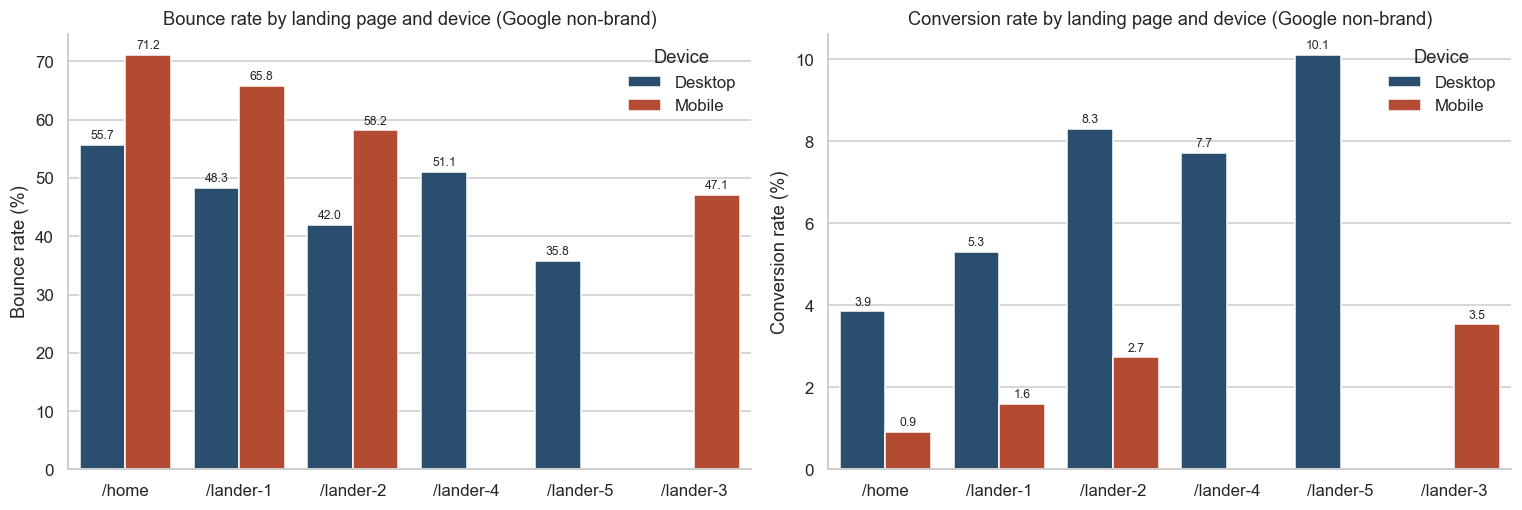

In [42]:
# Create two charts side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
# Left chart: bounce rate by landing page, split by device
sns.barplot(data=lp_tbl, x="landing_page", y="bounce_rate_pct", hue="device_type", palette=[PALETTE[0], PALETTE[3]], ax=axes[0])
# Add title and axis labels to the left chart
axes[0].set(title="Bounce rate by landing page and device (Google non-brand)", xlabel="", ylabel="Bounce rate (%)")
# Right chart: conversion rate by landing page, split by device
sns.barplot(data=lp_tbl, x="landing_page", y="conversion_rate_pct", hue="device_type", palette=[PALETTE[0], PALETTE[3]], ax=axes[1])
# Add title and axis labels to the right chart
axes[1].set(title="Conversion rate by landing page and device (Google non-brand)", xlabel="", ylabel="Conversion rate (%)")
# Write the values above the bars of both charts
for ax in axes:
    # Add numeric labels to every bar group
    for container in ax.containers:
        # Label each bar with one decimal
        ax.bar_label(container, fmt="%.1f", padding=2, fontsize=8)
    # Place the legend outside the way of the bars
    ax.legend(title="Device", frameon=False)
# Save and show the figure
save_fig("fig08_landing_pages_by_device")

In [43]:
# Fair desktop test: compare /lander-2 and /lander-5 only while BOTH were live at the same time (Google non-brand, desktop)
d = landing[(landing["channel"] == "Google nonbrand") & (landing["device_type"] == "Desktop")]
# The overlap starts when /lander-5 first appeared
ov_start = d.loc[d["landing_page"] == "/lander-5", "landing_time"].min()
# The overlap ends when /lander-2 was last shown to desktop visitors
ov_end = d.loc[d["landing_page"] == "/lander-2", "landing_time"].max()
# Keep the two pages inside the overlap window
ov = d[d["landing_page"].isin(["/lander-2", "/lander-5"]) & d["landing_time"].between(ov_start, ov_end)]
# Summarise sessions, orders, conversion and bounce for each page
lander_ab = ov.groupby("landing_page").agg(sessions=("website_session_id", "count"), orders=("converted", "sum"), bounced=("bounced", "sum")).reset_index()
# Conversion rate and bounce rate of each page
lander_ab["conversion_rate_pct"] = lander_ab["orders"] / lander_ab["sessions"] * 100
# Bounce rate of each page
lander_ab["bounce_rate_pct"] = lander_ab["bounced"] / lander_ab["sessions"] * 100
# Print the overlap period and show the result
print(f"Overlap period: {ov_start.date()} to {ov_end.date()}")
# Display the like-for-like landing page A/B result
display(lander_ab)

Overlap period: 2014-08-02 to 2014-11-10


,landing_page,sessions,orders,bounced,conversion_rate_pct,bounce_rate_pct
0,/lander-2,11584,970,4924,8.37,42.51
1,/lander-5,11530,1162,4053,10.08,35.15


In [44]:
# Funnel by device: sessions reaching each stage, split by mobile and desktop
dev_map = sessions.set_index("website_session_id")["device_type"]
# Attach the device to every funnel pageview (one row per session and step)
steps = pv.drop_duplicates(["website_session_id", "step"])[["website_session_id", "step"]].copy()
# Look up the device of each session
steps["device_type"] = steps["website_session_id"].map(dev_map)
# Count sessions per step and device and put the steps in funnel order
fd = steps.groupby(["step", "device_type"])["website_session_id"].nunique().unstack().reindex(FUNNEL_ORDER)
# Convert counts to "% of previous step" so that the two devices can be compared stage by stage
fd_rate = fd / fd.shift() * 100
# Rename the columns for clarity
fd_rate.columns = [f"{c} (% of previous step)" for c in fd_rate.columns]
# Display the stage-by-stage continuation rates by device
display(fd_rate.iloc[1:])

,Desktop (% of previous step),Mobile (% of previous step)
step,,
Products page,58.09,46.89
Product detail page,84.20,67.78
Cart,45.73,41.93
Shipping,70.15,59.65
Billing,83.03,70.60
Order placed,63.20,54.07


In [45]:
# Look at the two billing page versions: for every session keep the FIRST billing page it saw
bill_first = pv[pv["pageview_url"].isin(["/billing", "/billing-2"])].drop_duplicates("website_session_id")[["website_session_id", "pageview_url", "created_at"]]
# A fair A/B comparison only includes the period when BOTH versions were live at the same time
window_start = bill_first.loc[bill_first["pageview_url"] == "/billing-2", "created_at"].min()
# The end of the overlap is the last time the original billing page was shown
window_end = bill_first.loc[bill_first["pageview_url"] == "/billing", "created_at"].max()
# Keep only sessions in the overlap period
bill_win = bill_first[(bill_first["created_at"] >= window_start) & (bill_first["created_at"] <= window_end)].copy()
# Sessions that completed the order (reached the thank-you page)
placed_sessions = set(pv.loc[pv["step"] == "Order placed", "website_session_id"])
# Flag whether each billing session ended in an order
bill_win["ordered"] = bill_win["website_session_id"].isin(placed_sessions).astype(int)
# Summarise the two versions
bill_tbl = bill_win.groupby("pageview_url").agg(sessions=("website_session_id", "count"), orders=("ordered", "sum")).reset_index()
# Billing-to-order rate of each version
bill_tbl["billing_to_order_pct"] = bill_tbl["orders"] / bill_tbl["sessions"] * 100
# Print the overlap period used
print(f"Overlap period: {window_start.date()} to {window_end.date()}")
# Display the billing A/B table
display(bill_tbl)

Overlap period: 2012-09-10 to 2013-01-05


,pageview_url,sessions,orders,billing_to_order_pct
0,/billing,1663,750,45.10
1,/billing-2,1657,1029,62.10


In [46]:
# Store the funnel numbers used in the narrative
fn = funnel["pct_of_previous_step"]
# Pick the stage with the largest drop-off after the landing page
worst_step = funnel["drop_off_pct"].iloc[1:].idxmax()
# Index the billing table
bt = bill_tbl.set_index("pageview_url")
# Save the numbers
M.update(fn_products=fn["Products page"], fn_detail=fn["Product detail page"], fn_cart=fn["Cart"], fn_ship=fn["Shipping"], fn_bill=fn["Billing"], fn_order=fn["Order placed"],
         worst_step=worst_step, worst_drop=funnel.loc[worst_step, "drop_off_pct"], bounce_overall=landing["bounced"].mean(),
         bill1=bt.loc["/billing", "billing_to_order_pct"], bill2=bt.loc["/billing-2", "billing_to_order_pct"],
         bill_window=f"{window_start.strftime('%d %b %Y')} to {window_end.strftime('%d %b %Y')}", bill_n=int(bt["sessions"].sum()))
# Index the like-for-like landing page table by page and device
lpi = lp_tbl.set_index(["landing_page", "device_type"])
# Gap in continuation rate between desktop and mobile at every funnel stage (percentage points)
gap = (fd_rate.iloc[1:, 0] - fd_rate.iloc[1:, 1]).sort_values(ascending=False)
# Store the landing-page and device-funnel numbers
M.update(l5_desk_cvr=lpi.loc[("/lander-5", "Desktop"), "conversion_rate_pct"], l5_desk_bounce=lpi.loc[("/lander-5", "Desktop"), "bounce_rate_pct"],
         l5_first=lpi.loc[("/lander-5", "Desktop"), "first_used"], home_desk_cvr=lpi.loc[("/home", "Desktop"), "conversion_rate_pct"],
         home_mob_cvr=lpi.loc[("/home", "Mobile"), "conversion_rate_pct"], l3_mob_cvr=lpi.loc[("/lander-3", "Mobile"), "conversion_rate_pct"],
         l3_mob_bounce=lpi.loc[("/lander-3", "Mobile"), "bounce_rate_pct"], home_mob_bounce=lpi.loc[("/home", "Mobile"), "bounce_rate_pct"],
         la2_cvr=lander_ab.set_index("landing_page").loc["/lander-2", "conversion_rate_pct"], la5_cvr=lander_ab.set_index("landing_page").loc["/lander-5", "conversion_rate_pct"],
         la2_bounce=lander_ab.set_index("landing_page").loc["/lander-2", "bounce_rate_pct"], la5_bounce=lander_ab.set_index("landing_page").loc["/lander-5", "bounce_rate_pct"],
         la_window=f"{ov_start.strftime('%d %b %Y')} to {ov_end.strftime('%d %b %Y')}", la_n=int(lander_ab["sessions"].sum()),
         mob_best_cvr=lpi.loc[("/lander-3", "Mobile"), "conversion_rate_pct"], desk_best_cvr=lpi.loc[("/lander-5", "Desktop"), "conversion_rate_pct"],
         gap_step=gap.index[0], gap_desk=fd_rate.loc[gap.index[0]].iloc[0], gap_mob=fd_rate.loc[gap.index[0]].iloc[1],
         gap2_step=gap.index[1], gap2_desk=fd_rate.loc[gap.index[1]].iloc[0], gap2_mob=fd_rate.loc[gap.index[1]].iloc[1])

**Findings - sessions to orders**
- **6.8%** of all sessions end in an order (**32,313 orders from 472,871 sessions**). The rate climbed from 4.1% in 2012 to 7.2% in 2014 and 8.4% in early 2015.
- **Funnel (each figure is the share of the previous stage):** 55% of landing sessions reach the products page, 80% of those open a product, 45% go on to the cart, 68% continue to shipping, 81% reach billing and 62% complete the order. The two biggest leaks are **product page to cart** (55% leave) and **landing page to products page** (45% leave).
- **The biggest desktop-vs-mobile gap is at the step into "Product detail page"**: 84% of desktop sessions continue to that stage versus 68% of mobile sessions (next largest gap: "Billing", 83% vs 71%). Mobile visitors fall behind at *every* stage, not at a single broken step.
- **Bounce rate** is 45% overall: nearly half of all visitors leave after one page, so landing-page quality matters.
- **Landing pages:** pages were served to different devices and periods, so we compare like with like. On desktop, while `/lander-2` and `/lander-5` ran side by side (02 Aug 2014 to 10 Nov 2014, 23,114 Google non-brand sessions), `/lander-5` converted 10.1% vs 8.4% and bounced 35% vs 43% (significance tested in Task 3). On mobile, even the best (latest) page, `/lander-3`, converts only 3.5% against 10.1% for the best desktop page, so landing-page design alone has not closed the mobile gap.
- **Billing page test:** during the overlap period (10 Sep 2012 to 05 Jan 2013, 3,320 sessions) the newer `/billing-2` page converted 62.1% of billing sessions versus 45.1% for `/billing` (significance tested in Task 3).

## 2.7 Which products have the highest refund activity?

In [47]:
# Display refund activity by product (refund count, rate and dollar value)
refund_tbl = prod[["product_name", "short_name", "units", "refunded_units", "refund_rate_pct", "refunds"]].copy()
# Share of all refund dollars that each product causes
refund_tbl["share_of_refund_dollars_pct"] = refund_tbl["refunds"] / refund_tbl["refunds"].sum() * 100
# Sort by refund rate, highest first
refund_tbl = refund_tbl.sort_values("refund_rate_pct", ascending=False)
# Display the refund table
display(refund_tbl)

,product_name,short_name,units,refunded_units,refund_rate_pct,refunds,share_of_refund_dollars_pct
2,The Birthday Sugar Panda,Sugar Panda,4985,301,6.04,"13,842.99",16.22
0,The Original Mr. Fuzzy,Mr. Fuzzy,24226,1237,5.11,"61,837.63",72.46
1,The Forever Love Bear,Love Bear,5796,129,2.23,"7,738.71",9.07
3,The Hudson River Mini bear,Mini Bear,5018,64,1.28,"1,919.36",2.25


In [48]:
# Days between order and refund for every refunded item
lag = refunds.merge(items[["order_item_id", "created_at"]], on="order_item_id", suffixes=("_refund", "_order"))
# Convert the time difference into days
lag["days_to_refund"] = (lag["created_at_refund"] - lag["created_at_order"]).dt.days
# Share of refunds that equal the full item price (full refunds)
full_refund = refunds.merge(order_items[["order_item_id", "price_usd"]], on="order_item_id")
# Compute the full-refund share
full_share = np.isclose(full_refund["refund_amount_usd"], full_refund["price_usd"]).mean()
# Overall refund rate and value as a share of revenue
overall_refund_rate = items["is_refunded"].mean()
# Refund dollars as a share of gross revenue
refund_pct_rev = refunds["refund_amount_usd"].sum() / orders["price_usd"].sum()
# Print the refund statistics
print(f"Refunded items: {int(items['is_refunded'].sum()):,} of {len(items):,} ({pct(overall_refund_rate)}) | refund value {money(refunds['refund_amount_usd'].sum())} = {pct(refund_pct_rev)} of gross revenue")
# Print the timing and size of refunds
print(f"Refund timing: median {lag['days_to_refund'].median():.0f} days after order (range {lag['days_to_refund'].min()}-{lag['days_to_refund'].max()}) | full refunds: {pct(full_share, 0)}")
# Refund rate by order month and product (months with at least 100 items sold)
rate_m = items.groupby(["month", "short_name"]).agg(items_sold=("order_item_id", "count"), refund_rate=("is_refunded", "mean")).reset_index()
# Keep months with enough volume and complete months only
rate_m = rate_m[(rate_m["items_sold"] >= 100) & (rate_m["month"] <= LAST_FULL_MONTH)]
# Store the results
M.update(overall_refund_rate=overall_refund_rate, refund_pct_rev=refund_pct_rev, refund_lag_median=lag["days_to_refund"].median(),
         full_refund_share=full_share, refund_total_items=int(items["is_refunded"].sum()))

Refunded items: 1,731 of 40,025 (4.3%) | refund value $85,339 = 4.4% of gross revenue
Refund timing: median 9 days after order (range 2-16) | full refunds: 100%


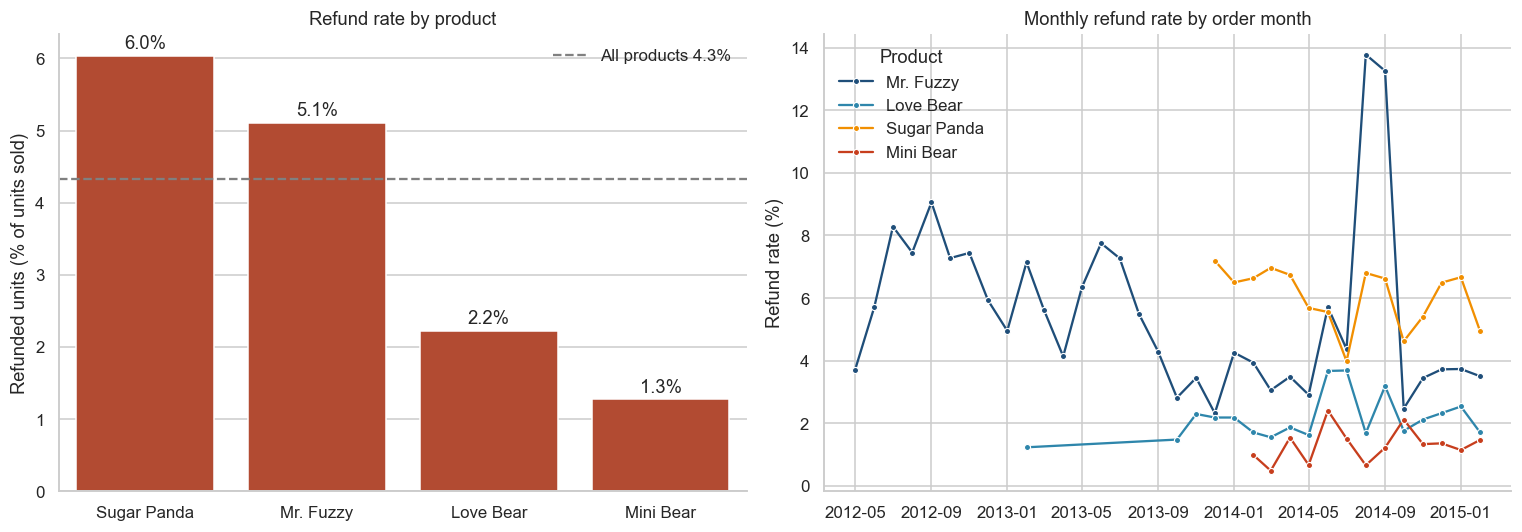

In [49]:
# Create two charts side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# Left chart: refund rate by product, highest first
sns.barplot(data=refund_tbl, x="short_name", y="refund_rate_pct", color=PALETTE[3], ax=axes[0])
# Draw the overall refund rate as a dashed reference line
axes[0].axhline(overall_refund_rate * 100, ls="--", color="grey", label=f"All products {overall_refund_rate*100:.1f}%")
# Write the values above the bars
axes[0].bar_label(axes[0].containers[0], fmt="%.1f%%", padding=2)
# Add title and axis labels to the left chart
axes[0].set(title="Refund rate by product", xlabel="", ylabel="Refunded units (% of units sold)")
# Show the legend
axes[0].legend(frameon=False)
# Right chart: monthly refund rate per product, in percent
sns.lineplot(data=rate_m.assign(refund_rate=rate_m["refund_rate"] * 100), x="month", y="refund_rate", hue="short_name", palette=PALETTE[:4], marker="o", ms=4, ax=axes[1])
# Add title and axis labels to the right chart
axes[1].set(title="Monthly refund rate by order month", xlabel="", ylabel="Refund rate (%)")
# Show a clean legend
axes[1].legend(title="Product", frameon=False)
# Save and show the figure
save_fig("fig09_refunds_by_product")

In [50]:
# Monthly refund history of the best seller
fuzzy_m = rate_m[rate_m["short_name"] == "Mr. Fuzzy"].set_index("month")
# The two months with the highest refund rate (candidates for a refund "episode")
spike = fuzzy_m.nlargest(2, "refund_rate")
# Start and end of the spike
spike_start, spike_end = spike.index.min(), spike.index.max()
# Baseline = average refund rate in the surrounding months of the same period (Jan 2014 - Feb 2015, excluding the spike)
base = fuzzy_m.loc["2014-01-01":"2015-02-01"].drop(spike.index)
# Baseline refund rate weighted by items sold
base_rate = (base["refund_rate"] * base["items_sold"]).sum() / base["items_sold"].sum()
# Actual refunded items during the spike
actual = (spike["refund_rate"] * spike["items_sold"]).sum()
# Refunded items that would be expected at the baseline rate
expected = base_rate * spike["items_sold"].sum()
# Excess refunds and their dollar value (full refunds at the item price of 49.99)
excess_items = actual - expected
# Dollar value of the excess refunds
excess_usd = excess_items * items.loc[items["short_name"] == "Mr. Fuzzy", "price_usd"].median()
# Refund rate of Mr. Fuzzy by year (all orders)
refund_year = items.groupby(["year", "short_name"])["is_refunded"].mean().unstack() * 100
# Display refund rate by year and product
display(refund_year)
# Print the spike analysis
print(f"Spike months: {spike_start:%b %Y} - {spike_end:%b %Y} | rates: {', '.join(f'{v*100:.1f}%' for v in spike['refund_rate'])} | baseline {base_rate*100:.1f}%")
# Print the estimated excess
print(f"Estimated excess refunds: {excess_items:,.0f} items = {money(excess_usd)}")
# Index the refund table for lookup
rt = refund_tbl.set_index("short_name")
# Save results
M.update(spike_months=f"{spike_start:%B}-{spike_end:%B %Y}", spike_rate=spike["refund_rate"].mean(), base_rate=base_rate, excess_items=excess_items, excess_usd=excess_usd,
         fuzzy_refund_2012=refund_year.loc[2012, "Mr. Fuzzy"], fuzzy_refund_2014=refund_year.loc[2014, "Mr. Fuzzy"],
         panda_refund=rt.loc["Sugar Panda", "refund_rate_pct"], fuzzy_refund=rt.loc["Mr. Fuzzy", "refund_rate_pct"], love_refund=rt.loc["Love Bear", "refund_rate_pct"],
         mini_refund=rt.loc["Mini Bear", "refund_rate_pct"], fuzzy_refund_share=rt.loc["Mr. Fuzzy", "share_of_refund_dollars_pct"] / 100,
         refund_top_name=refund_tbl.iloc[0]["short_name"])

short_name,Love Bear,Mini Bear,Mr. Fuzzy,Sugar Panda
year,,,,
2012,NaN,NaN,6.88,NaN
2013,2.19,NaN,4.83,7.19
2014,2.27,1.33,5.31,5.95
2015,2.14,1.14,3.53,6.17


Spike months: Aug 2014 - Sep 2014 | rates: 13.8%, 13.3% | baseline 3.7%
Estimated excess refunds: 198 items = $9,909


**Findings - refunds**
- Overall, **4.3%** of units sold are refunded (1,731 items), costing $85,339 or 4.4% of gross revenue. Refunds are quick (median 9 days after the order) and 100% are full refunds.
- **Highest refund rate: Sugar Panda (6.0%)**, followed by Mr. Fuzzy (5.1%), Love Bear (2.2%) and Mini Bear (1.3%).
- **Highest refund dollars: Mr. Fuzzy** (72% of all refund dollars) simply because it sells the most units.
- **A refund episode hit Mr. Fuzzy in August-September 2014:** the refund rate jumped to about 13.5% versus a normal 3.7%, then fell straight back. That is roughly 198 extra refunds worth about $9,909. A sudden, temporary spike like this points to a **product-quality or supplier problem** (for example one defective batch) rather than a permanent customer preference, and the fast recovery suggests it was fixed.
- **Long-run improvement:** the Mr. Fuzzy refund rate fell from 6.9% in 2012 to 5.3% in 2014 (including the spike), while Sugar Panda stays the structurally highest-refund product.

## 2.8 Are there noticeable differences between new and returning website sessions?

In [51]:
# Aggregate sessions, orders and revenue by visitor type (new vs returning)
visitor = sessions.groupby("visitor_type").agg(sessions=("website_session_id", "count"), orders=("converted", "sum"), revenue=("revenue_usd", "sum")).reset_index()
# Share of sessions by visitor type
visitor["share_of_sessions_pct"] = visitor["sessions"] / visitor["sessions"].sum() * 100
# Conversion rate by visitor type
visitor["conversion_rate_pct"] = visitor["orders"] / visitor["sessions"] * 100
# Revenue per session by visitor type
visitor["revenue_per_session"] = visitor["revenue"] / visitor["sessions"]
# Average order value by visitor type
visitor["aov"] = visitor["revenue"] / visitor["orders"]
# Display the new vs returning comparison
display(visitor)

,visitor_type,sessions,orders,revenue,share_of_sessions_pct,conversion_rate_pct,revenue_per_session,aov
0,New,394318,26164,"1,566,274.92",83.39,6.64,3.97,59.86
1,Returning,78553,6149,"372,234.83",16.61,7.83,4.74,60.54


In [52]:
# Channel mix of new versus returning sessions (column percentages)
mix_channel = pd.crosstab(sessions["channel"], sessions["visitor_type"], normalize="columns") * 100
# Device mix of new versus returning sessions (column percentages)
mix_device = pd.crosstab(sessions["device_type"], sessions["visitor_type"], normalize="columns") * 100
# Share of returning sessions by quarter
ret_q = sessions.groupby("quarter")["is_repeat_session"].mean() * 100
# Display the channel mix
display(mix_channel)
# Display the device mix
display(mix_device)

visitor_type,New,Returning
channel,,
Bing nonbrand,13.93,0.00
Direct,3.73,32.10
Google nonbrand,71.69,0.00
Organic search,4.13,34.51
Paid brand search,3.81,33.38
Social (Socialbook),2.71,0.00


visitor_type,New,Returning
device_type,,
Desktop,70.33,63.30
Mobile,29.67,36.70


In [53]:
# New and returning visitors do not arrive through the same channels, so compare them within the same (brand-aware) channels
shared = sessions[sessions["channel"].isin(["Direct", "Organic search", "Paid brand search"])]
# Summarise sessions, orders and conversion rate by channel and visitor type
shared_tbl = shared.groupby(["channel", "visitor_type"]).agg(sessions=("website_session_id", "count"), orders=("converted", "sum"), conversion_rate_pct=("converted", lambda s: s.mean() * 100)).reset_index()
# Display the like-for-like comparison inside each channel
display(shared_tbl)
# Pool the three channels by visitor type
shared_vt = shared.groupby("visitor_type").agg(sessions=("website_session_id", "count"), orders=("converted", "sum"))
# Conversion rate of new and returning visitors within the same channels
shared_vt["conversion_rate_pct"] = shared_vt["orders"] / shared_vt["sessions"] * 100
# Display the pooled like-for-like comparison
display(shared_vt)

,channel,visitor_type,sessions,orders,conversion_rate_pct
0,Direct,New,14700,972,6.61
1,Direct,Returning,25217,1884,7.47
2,Organic search,New,16299,1138,6.98
3,Organic search,Returning,27112,2124,7.83
4,Paid brand search,New,15019,1071,7.13
5,Paid brand search,Returning,26224,2141,8.16


,sessions,orders,conversion_rate_pct
visitor_type,,,
New,46018,3181,6.91
Returning,78553,6149,7.83


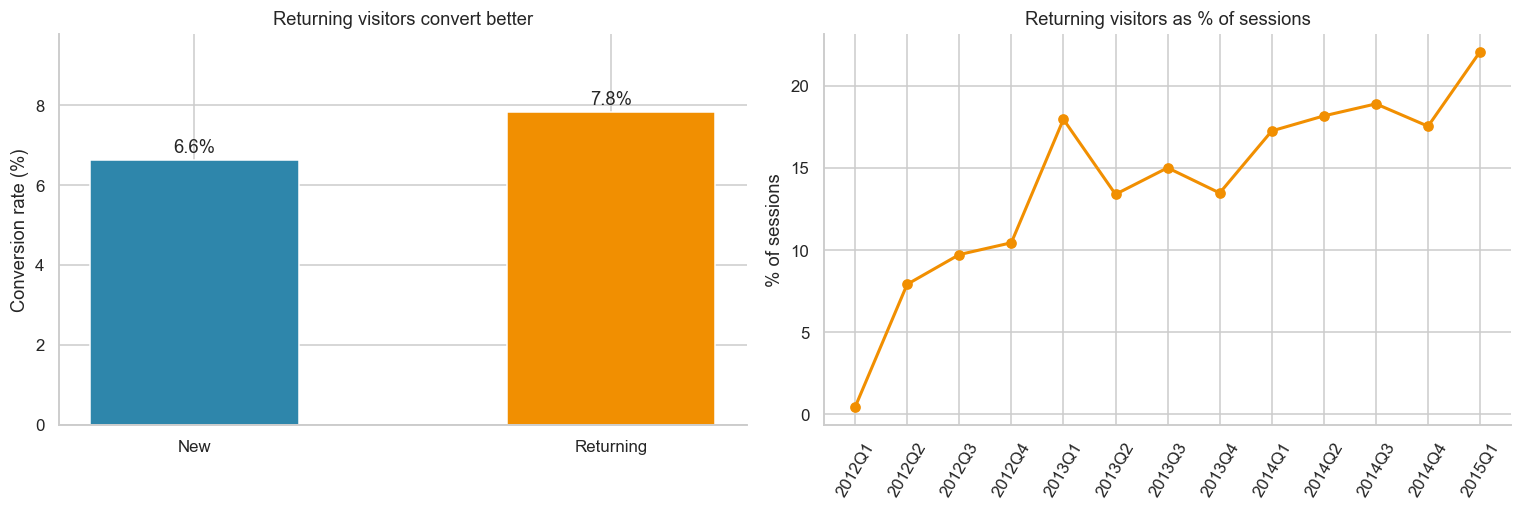

In [54]:
# Create two charts side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
# Left chart: conversion rate and revenue per session for new vs returning visitors
vt = visitor.set_index("visitor_type")
# Draw conversion-rate bars
axes[0].bar(vt.index, vt["conversion_rate_pct"], color=[PALETTE[1], PALETTE[2]], width=0.5)
# Write the values on top of the bars
axes[0].bar_label(axes[0].containers[0], fmt="%.1f%%", padding=2)
# Add title and axis labels to the left chart
axes[0].set(title="Returning visitors convert better", ylabel="Conversion rate (%)", xlabel="", ylim=(0, vt["conversion_rate_pct"].max() * 1.25))
# Right chart: share of returning sessions over time
axes[1].plot(ret_q.index, ret_q.values, marker="o", color=PALETTE[2], lw=2)
# Add title and axis labels to the right chart
axes[1].set(title="Returning visitors as % of sessions", xlabel="", ylabel="% of sessions")
# Rotate the quarter labels
axes[1].tick_params(axis="x", rotation=60)
# Save and show the figure
save_fig("fig10_new_vs_returning")

In [55]:
# Index the visitor table for lookup
vv = visitor.set_index("visitor_type")
# Store the numbers used in the narrative
M.update(new_cvr=vv.loc["New", "conversion_rate_pct"], ret_cvr=vv.loc["Returning", "conversion_rate_pct"], ret_share=vv.loc["Returning", "share_of_sessions_pct"] / 100,
         new_rps=vv.loc["New", "revenue_per_session"], ret_rps=vv.loc["Returning", "revenue_per_session"], new_aov=vv.loc["New", "aov"], ret_aov=vv.loc["Returning", "aov"],
         ret_q_2012=ret_q["2012Q2"], ret_q_2014q4=ret_q["2014Q4"], ret_mobile=mix_device.loc["Mobile", "Returning"] / 100, new_mobile=mix_device.loc["Mobile", "New"] / 100,
         ret_direct=mix_channel.loc["Direct", "Returning"] / 100, ret_organic=mix_channel.loc["Organic search", "Returning"] / 100,
         ret_brand=mix_channel.loc["Paid brand search", "Returning"] / 100, shared_new_cvr=shared_vt.loc["New", "conversion_rate_pct"], shared_ret_cvr=shared_vt.loc["Returning", "conversion_rate_pct"])
# Write the verdict sentence depending on how large the like-for-like gap is
gap_pp = M["shared_ret_cvr"] - M["shared_new_cvr"]
# A gap of under 0.5 percentage points is treated as small
M["shared_verdict"] = ("most of the headline advantage of returning visitors comes from the channels they use, not from being returning visitors. The extra conversion attributable to returning status is small (" + f"{gap_pp:+.1f}" + " percentage points)." if abs(gap_pp) < 0.5
                       else "returning visitors keep a genuine edge of " + f"{gap_pp:+.1f}" + " percentage points even inside the same channels (tested in Task 3).")

**Findings - new vs returning sessions**
- Returning visitors are **17%** of sessions but convert better: **7.8%** vs **6.6%** for new visitors, and earn $4.74 vs $3.97 revenue per session. Order values are similar ($60.54 vs $59.86), so the benefit comes from higher purchase likelihood.
- The returning share is rising (8% of sessions in 2012Q2 to 18% in 2014Q4), a sign of growing brand awareness.
- **Returning sessions arrive only through brand-aware channels** (direct 32%, organic 35%, paid brand 33%); none are attributed to non-brand search or social. They are also more mobile (37% of returning vs 30% of new sessions).
- **Like-for-like check:** inside those same three channels, new visitors convert at 6.9% and returning visitors at 7.8%. So returning visitors keep a genuine edge of +0.9 percentage points even inside the same channels (tested in Task 3).

---
# Task 3: Statistical Analysis and Visualisation
## 3.1 Descriptive statistics

In [56]:
# Choose the numeric order-level columns to describe
num_cols = ["price_usd", "items_purchased", "cogs_usd", "gross_profit_usd", "order_refund_usd"]
# Standard descriptive statistics (count, mean, std, quartiles, min, max)
desc = orders[num_cols].describe().T
# Add the median explicitly (it equals the 50% quartile) for clarity
desc["median"] = orders[num_cols].median()
# Add skewness: > 0 means a long tail of large values
desc["skewness"] = orders[num_cols].skew()
# Add the coefficient of variation (std / mean): a scale-free measure of spread
desc["coef_variation"] = desc["std"] / desc["mean"]
# Display the order-level descriptive statistics
display(desc)

,count,mean,std,min,25%,50%,75%,max,median,skewness,coef_variation
price_usd,"32,313.00",59.99,17.81,29.99,49.99,49.99,59.99,109.98,49.99,1.34,0.30
items_purchased,"32,313.00",1.24,0.43,1.00,1.00,1.00,1.00,2.00,1.00,1.23,0.34
cogs_usd,"32,313.00",22.36,6.24,9.49,19.49,19.49,22.49,41.98,19.49,1.28,0.28
gross_profit_usd,"32,313.00",37.64,11.75,20.50,30.50,30.50,37.50,69.00,30.50,1.32,0.31
order_refund_usd,"32,313.00",2.64,11.21,0.00,0.00,0.00,0.00,109.98,0.00,4.09,4.24


In [57]:
# Build a daily table of sessions, orders and revenue
daily = pd.concat([sessions.groupby("date").size().rename("sessions"),
                   orders.groupby("date").agg(orders=("order_id", "count"), revenue=("price_usd", "sum"))], axis=1).fillna(0)
# Keep only complete days (the first and last day of the data are partial)
daily = daily.loc[FIRST_FULL_DAY:LAST_FULL_DAY].copy()
# Daily conversion rate in percent
daily["cvr_pct"] = daily["orders"] / daily["sessions"] * 100
# Calendar year of every day
daily["year"] = daily.index.year
# Descriptive statistics of the daily metrics for the two complete years
daily_desc = daily[daily["year"].isin([2013, 2014])].groupby("year")[["sessions", "orders", "revenue", "cvr_pct"]].agg(["mean", "median", "std", "min", "max"]).T
# Display the daily statistics by year
display(daily_desc)

year                 2013      2014
sessions mean      308.99    639.51
         median    296.00    660.00
         std       265.01    376.95
         min        89.00    225.00
         max     3,963.00  5,175.00
orders   mean       20.40     46.19
         median     20.00     45.00
         std        15.60     30.57
         min         2.00     10.00
         max       218.00    417.00
revenue  mean    1,077.39  2,946.88
         median  1,009.80  2,855.39
         std       847.29  2,003.35
         min        99.98    545.89
         max    11,707.74 27,404.23
cvr_pct  mean        6.60      7.14
         median      6.60      7.13
         std         1.64      1.27
         min         1.32      3.78
         max        12.12     12.10

In [58]:
# Descriptive statistics of pages viewed per session (sessions with complete pageview data)
pps = pages_per_session.describe()
# Share of sessions that viewed only one page
single_page = (pages_per_session == 1).mean()
# Print the pages-per-session statistics
print(f"Pages per session: mean {pps['mean']:.2f}, median {pps['50%']:.0f}, max {pps['max']:.0f} | single-page sessions: {pct(single_page)}")
# Frequency table of the categorical variables (share of sessions)
for col in ["device_type", "visitor_type", "channel"]:
    # Show the percentage distribution of each categorical column
    print("\n" + (sessions[col].value_counts(normalize=True) * 100).round(1).to_string())
# Store the daily means for the report
M.update(daily_orders_2014=daily.loc[daily["year"] == 2014, "orders"].mean(), daily_rev_2014=daily.loc[daily["year"] == 2014, "revenue"].mean(),
         daily_sessions_2014=daily.loc[daily["year"] == 2014, "sessions"].mean(), order_median=orders["price_usd"].median(), order_mean=orders["price_usd"].mean())

Pages per session: mean 2.49, median 2, max 7 | single-page sessions: 45.4%

device_type
Desktop   69.20
Mobile    30.80

visitor_type
New         83.40
Returning   16.60

channel
Google nonbrand       59.80
Bing nonbrand         11.60
Organic search         9.20
Paid brand search      8.70
Direct                 8.40
Social (Socialbook)    2.30


**Interpretation**
- The typical order is **$50** (median) and the mean is **$59.99**. The mean is higher than the median because of the two-item orders: the order-value distribution is *right-skewed* with only two distinct sizes (one item, two items).
- In 2014 the shop received about **640 sessions**, **46 orders** and **$2,947 revenue per day** on average.
- Daily revenue has a high coefficient of variation because of the strong upward trend and the weekday/holiday seasonality analysed below.

## 3.2 Relationship between website traffic and orders

In [59]:
# Pearson correlation (linear relationship) between daily sessions and daily orders
pear = stats.pearsonr(daily["sessions"], daily["orders"])
# Spearman correlation (rank-based, robust to outliers and non-linearity)
spear = stats.spearmanr(daily["sessions"], daily["orders"])
# Simple linear regression: orders = intercept + slope * sessions
reg = stats.linregress(daily["sessions"], daily["orders"])
# Print the overall correlation results
print(f"Pearson r = {pear.statistic:.3f} (p {'< 0.001' if pear.pvalue < 0.001 else '= ' + format(pear.pvalue, '.3f')}) | Spearman rho = {spear.statistic:.3f} | R-squared = {reg.rvalue**2:.3f}")
# Print the regression slope converted to "orders per 100 additional sessions"
print(f"Regression slope: {reg.slope * 100:.2f} extra orders for every 100 extra sessions")
# Both series trend upwards over time, so also test the relationship WITHIN each year
within = {int(y): float(g["sessions"].corr(g["orders"])) for y, g in daily.groupby("year")}
# Print the within-year correlations
print("Within-year Pearson r:", {k: round(v, 3) for k, v in within.items()})
# And test the day-to-day CHANGES, which removes the common time trend
diff_corr = daily[["sessions", "orders"]].diff().dropna().corr().iloc[0, 1]
# Print the correlation of daily changes
print(f"Correlation of day-to-day changes: {diff_corr:.3f}")
# Weekly totals smooth out weekday effects
weekly = daily[["sessions", "orders"]].resample("W").sum()
# Print the weekly correlation
print(f"Weekly totals Pearson r: {weekly['sessions'].corr(weekly['orders']):.3f}")
# Store the results
M.update(r_daily=pear.statistic, r_p=pear.pvalue, r2_daily=reg.rvalue ** 2, slope_per100=reg.slope * 100, r_diff=diff_corr, r_week=weekly["sessions"].corr(weekly["orders"]),
         r_within_min=min(within.values()), r_within_max=max(within.values()))

Pearson r = 0.956 (p < 0.001) | Spearman rho = 0.953 | R-squared = 0.914
Regression slope: 7.43 extra orders for every 100 extra sessions
Within-year Pearson r: {2012: 0.97, 2013: 0.953, 2014: 0.971, 2015: 0.929}
Correlation of day-to-day changes: 0.941
Weekly totals Pearson r: 0.977


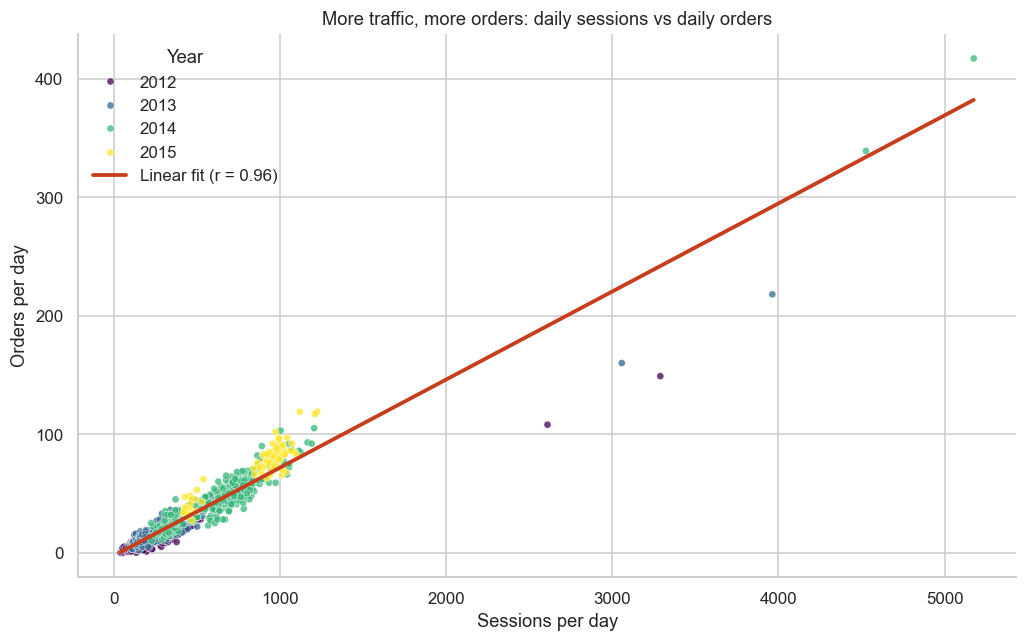

In [60]:
# Create the scatter plot of daily sessions versus daily orders
fig, ax = plt.subplots(figsize=(9.5, 6))
# Draw one point per day, coloured by year to reveal the growth over time
sns.scatterplot(data=daily.reset_index(), x="sessions", y="orders", hue="year", palette="viridis", s=22, alpha=0.75, ax=ax)
# Create x values for the regression line
xs = np.linspace(daily["sessions"].min(), daily["sessions"].max(), 100)
# Draw the fitted regression line
ax.plot(xs, reg.intercept + reg.slope * xs, color=PALETTE[3], lw=2.5, label=f"Linear fit (r = {pear.statistic:.2f})")
# Add title and axis labels
ax.set(title="More traffic, more orders: daily sessions vs daily orders", xlabel="Sessions per day", ylabel="Orders per day")
# Show the legend
ax.legend(title="Year", frameon=False)
# Save and show the figure
save_fig("fig11_traffic_vs_orders")

**Interpretation.** Daily sessions and daily orders are **very strongly correlated** (Pearson r = 0.96, R² = 0.91, p < 0.001): every extra 100 sessions bring about **7.4 extra orders**. Because both series trend upward, we double-checked: the relationship stays strong **within each year** (r between 0.93 and 0.97), in **day-to-day changes** (r = 0.94) and in **weekly totals** (r = 0.98). So traffic genuinely drives orders; the points drifting upward by colour also show that each year converts more traffic into orders than the one before. (Correlation shows association, not proof of causation.)

## 3.3 Comparing sales across different periods

In [61]:
# Like-for-like comparison: only 1 January to 18 March of each year (data ends on 19 March 2015)
def like_for_like(df):
    """Return True for rows between 1 Jan and 18 Mar (inclusive) of any year."""
    # Month of every row
    m = df["created_at"].dt.month
    # Day of the month of every row
    d = df["created_at"].dt.day
    # Months January and February, or March up to the 18th
    return (m < 3) | ((m == 3) & (d <= 18))

# Revenue and orders of the like-for-like window per year (2012 has no data before 19 March)
lfl_o = orders[like_for_like(orders) & (orders["year"] >= 2013)].groupby("year").agg(orders=("order_id", "count"), revenue=("price_usd", "sum"))
# Sessions of the like-for-like window per year
lfl_s = sessions[like_for_like(sessions) & (sessions["year"] >= 2013)].groupby("year").size().rename("sessions")
# Combine the tables
lfl = lfl_o.join(lfl_s)
# Conversion rate and growth rates versus the previous year
lfl["conversion_rate_pct"] = lfl["orders"] / lfl["sessions"] * 100
# Year-over-year revenue growth in percent
lfl["revenue_yoy_pct"] = lfl["revenue"].pct_change() * 100
# Year-over-year session growth in percent
lfl["sessions_yoy_pct"] = lfl["sessions"].pct_change() * 100
# Display the like-for-like (1 Jan - 18 Mar) comparison
display(lfl)
# Store the key result
M.update(lfl_15_vs_14=lfl.loc[2015, "revenue_yoy_pct"] / 100, lfl_14_vs_13=lfl.loc[2014, "revenue_yoy_pct"] / 100)

,orders,revenue,sessions,conversion_rate_pct,revenue_yoy_pct,sessions_yoy_pct
year,,,,,,
2013,1090,"56,959.10",17014,6.41,NaN,NaN
2014,2640,"163,088.95",40626,6.50,186.33,138.78
2015,5408,"339,763.69",64047,8.44,108.33,57.65


In [62]:
# Average DAILY revenue for each bimonthly period, so periods of different length are comparable
daily_rev = orders.groupby("date")["price_usd"].sum().reindex(pd.date_range(FIRST_FULL_DAY, LAST_FULL_DAY), fill_value=0)
# Helper that returns the daily revenue values for given months of a given year
def period(year, months):
    """Daily revenue values for the given months of a year."""
    # Select days of the requested year and months
    return daily_rev[(daily_rev.index.year == year) & (daily_rev.index.month.isin(months))]
# Collect the seasonal comparison for the full years 2013 and 2014 (and 2012 where available)
rows = []
# Loop over the years that contain the whole Jul-Dec period
for yr in [2012, 2013, 2014]:
    # Average daily revenue in July-August, September-October and November-December
    ja, so, nd = period(yr, [7, 8]).mean(), period(yr, [9, 10]).mean(), period(yr, [11, 12]).mean()
    # Mann-Whitney test: are Nov-Dec days different from Sep-Oct days?
    mw = stats.mannwhitneyu(period(yr, [11, 12]), period(yr, [9, 10]), alternative="two-sided")
    # Store the figures
    rows.append({"year": yr, "jul_aug_daily_rev": ja, "sep_oct_daily_rev": so, "nov_dec_daily_rev": nd,
                 "trend_growth_pct (SepOct vs JulAug)": (so / ja - 1) * 100, "holiday_uplift_pct (NovDec vs SepOct)": (nd / so - 1) * 100,
                 "excess_uplift_pp": ((nd / so) - (so / ja)) * 100, "mann_whitney_p": mw.pvalue})
# Convert to a DataFrame
season = pd.DataFrame(rows).set_index("year")
# Display the seasonality table
display(season)
# Store results (2013 and 2014 are the clean full years)
M.update(uplift_13=season.loc[2013, "holiday_uplift_pct (NovDec vs SepOct)"] / 100, uplift_14=season.loc[2014, "holiday_uplift_pct (NovDec vs SepOct)"] / 100,
         trend_14=season.loc[2014, "trend_growth_pct (SepOct vs JulAug)"] / 100, excess_14=season.loc[2014, "excess_uplift_pp"], excess_13=season.loc[2013, "excess_uplift_pp"],
         dec14_daily=period(2014, [12]).mean(), sepoct14_daily=season.loc[2014, "sep_oct_daily_rev"])

,jul_aug_daily_rev,sep_oct_daily_rev,nov_dec_daily_rev,trend_growth_pct (SepOct vs JulAug),holiday_uplift_pct (NovDec vs SepOct),excess_uplift_pp,mann_whitney_p
year,,,,,,,
2012,320.10,539.24,921.13,68.46,70.82,2.36,0.00
2013,"1,008.35","1,163.38","1,719.57",15.37,47.81,32.43,0.02
2014,"2,709.75","3,215.38","4,475.18",18.66,39.18,20.52,0.01


In [63]:
# Compare weekday and weekend revenue inside the single full year 2014 (so the long-term trend does not distort the test)
d14 = daily_rev[daily_rev.index.year == 2014]
# Daily revenue on weekdays (Monday-Friday)
wd = d14[d14.index.dayofweek < 5]
# Daily revenue on weekend days (Saturday-Sunday)
we = d14[d14.index.dayofweek >= 5]
# Non-parametric test, because daily revenue is not normally distributed
mw_week = stats.mannwhitneyu(wd, we, alternative="two-sided")
# Print the comparison
print(f"2014 average daily revenue: weekday {money(wd.mean())} vs weekend {money(we.mean())} (weekend = {we.mean() / wd.mean() * 100:.0f}% of a weekday) | Mann-Whitney p = {mw_week.pvalue:.1e}")
# Store the results
M.update(wd_rev=wd.mean(), we_rev=we.mean(), we_ratio=we.mean() / wd.mean(), mw_week_p=mw_week.pvalue)

2014 average daily revenue: weekday $3,504 vs weekend $1,548 (weekend = 44% of a weekday) | Mann-Whitney p = 7.6e-44


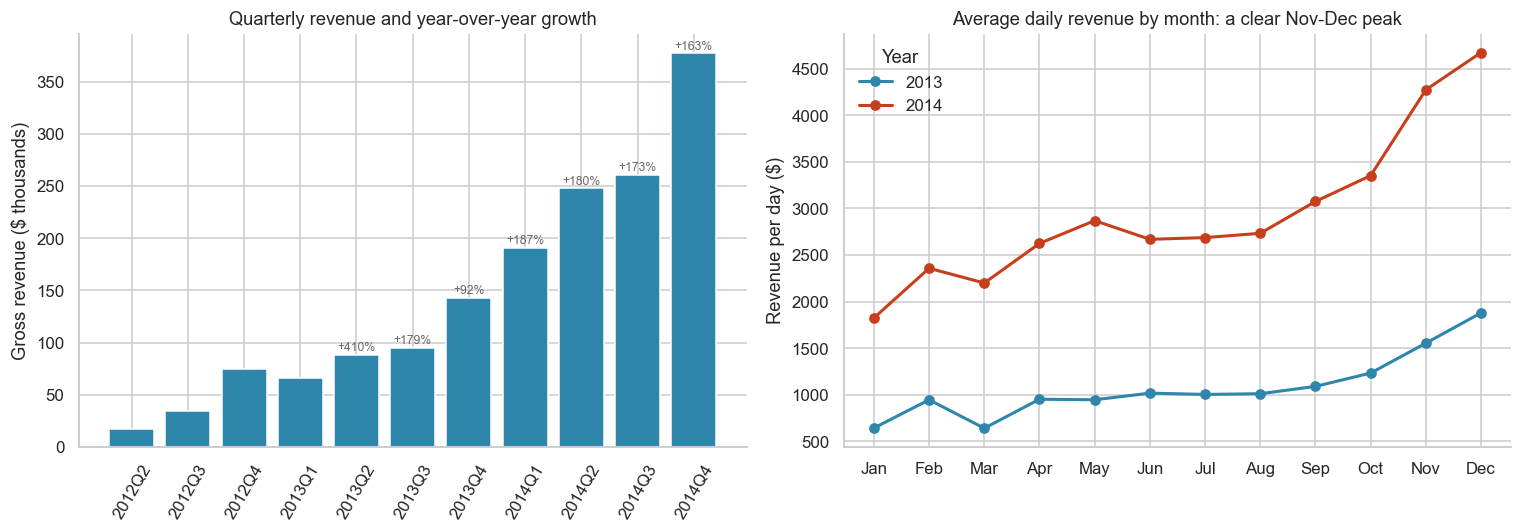

In [64]:
# Create two charts side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# Left chart: quarterly revenue for complete quarters with year-over-year growth labels
qc = qtr[qtr["complete"]].copy()
# Draw the bars
bars = axes[0].bar(qc["quarter"], qc["gross_revenue"] / 1000, color=PALETTE[1])
# Annotate each bar with its YoY growth (when available)
for bar, yoy in zip(bars, qc["yoy_growth_pct"]):
    # Skip the first four quarters that have no comparable previous-year quarter
    if not np.isnan(yoy):
        # Write the growth percentage above the bar
        axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 4, f"+{yoy:.0f}%", ha="center", fontsize=8, color="dimgrey")
# Add title and labels to the left chart
axes[0].set(title="Quarterly revenue and year-over-year growth", xlabel="", ylabel="Gross revenue ($ thousands)")
# Rotate the quarter labels
axes[0].tick_params(axis="x", rotation=60)
# Right chart: average daily revenue by calendar month for 2013 and 2014 (shows the seasonal shape)
seas = orders[orders["year"].isin([2013, 2014])].groupby(["year", orders["created_at"].dt.month])["price_usd"].sum().unstack(0)
# Convert monthly totals into daily averages by dividing by days in the month
seas = seas.div(pd.Series([31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31], index=range(1, 13)), axis=0)
# Draw one line per year
seas.plot(ax=axes[1], marker="o", color=[PALETTE[1], PALETTE[3]], lw=2)
# Label the months on the x-axis
axes[1].set_xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
# Add title and labels to the right chart
axes[1].set(title="Average daily revenue by month: a clear Nov-Dec peak", xlabel="", ylabel="Revenue per day ($)")
# Show the legend
axes[1].legend(title="Year", frameon=False)
# Save and show the figure
save_fig("fig12_period_comparison")

**Interpretation**
- **Year over year:** in the like-for-like window (1 Jan - 18 Mar) revenue grew +186% in 2014 and still +108% in 2015, so growth is **sustained, not slowing down sharply**.
- **Holiday seasonality:** average daily revenue in November-December was +39% above September-October in 2014 (+48% in 2013). Because the business was also growing anyway (+19% from July-August to September-October in 2014), the *extra* holiday effect is roughly 21 percentage points in 2014. The difference is statistically significant (see test table).
- **Weekday vs weekend:** in 2014 a weekend day brought only 44% of the revenue of a weekday ($1,548 vs $3,504), clearly significant (Mann-Whitney p < 0.001).

## 3.4 Relationship between product sales and refunds

In [65]:
# Contingency table: number of items refunded vs not refunded for every product
ct = pd.crosstab(items["short_name"], items["is_refunded"]).rename(columns={0: "not_refunded", 1: "refunded"})
# Chi-square test of independence: is the refund rate the same for all products?
chi = stats.chi2_contingency(ct)
# Cramer's V: effect size of the association between product and refund (0 = none, 1 = perfect)
cramers_v = np.sqrt(chi.statistic / (ct.values.sum() * (min(ct.shape) - 1)))
# Standardised residuals: positive = more refunds than expected, negative = fewer
resid = pd.DataFrame((ct.values - chi.expected_freq) / np.sqrt(chi.expected_freq), index=ct.index, columns=ct.columns)
# Print the test result
print(f"Chi-square = {chi.statistic:,.1f}, dof = {chi.dof}, p = {chi.pvalue:.1e}, Cramer's V = {cramers_v:.3f}")
# Display the counts and the residuals
display(ct)
# Display the standardised residuals of the refunded column
display(resid[["refunded"]].rename(columns={"refunded": "std_residual_refunded"}))

Chi-square = 245.6, dof = 3, p = 5.9e-53, Cramer's V = 0.078


is_refunded,not_refunded,refunded
short_name,,
Love Bear,5667,129
Mini Bear,4954,64
Mr. Fuzzy,22989,1237
Sugar Panda,4684,301


is_refunded,std_residual_refunded
short_name,
Love Bear,-7.68
Mini Bear,-10.39
Mr. Fuzzy,5.85
Sugar Panda,5.82


In [66]:
# Refund rate of primary items versus cross-sell (second) items, only after cross-selling started
post_items = items[items["created_at"] >= first_bundle]
# Summarise the two roles
role_tbl = post_items.groupby("item_role").agg(items=("order_item_id", "count"), refunded=("is_refunded", "sum"))
# Refund rate of each role
role_tbl["refund_rate_pct"] = role_tbl["refunded"] / role_tbl["items"] * 100
# Display the role comparison
display(role_tbl)
# Product-month table: units sold and units refunded per product and order month (complete months, products with at least 50 sales)
pm = items.groupby(["short_name", "month"]).agg(units=("order_item_id", "count"), refunded=("is_refunded", "sum")).reset_index()
# Keep complete months with enough volume
pm = pm[(pm["units"] >= 50) & (pm["month"] <= LAST_FULL_MONTH)].copy()
# Refund rate per product-month
pm["rate"] = pm["refunded"] / pm["units"]
# Correlation between units sold and refunded units: refunds scale with sales
r_units = stats.pearsonr(pm["units"], pm["refunded"])
# Correlation between units sold and the refund RATE: do bigger months have worse refund rates?
r_rate = stats.spearmanr(pm["units"], pm["rate"])
# Print both results
print(f"Units sold vs refunded units: Pearson r = {r_units.statistic:.2f} (p = {r_units.pvalue:.1e}, n = {len(pm)} product-months)")
# Print the second result
print(f"Units sold vs refund RATE: Spearman rho = {r_rate.statistic:.2f} (p = {r_rate.pvalue:.2f})")
# Store the results
M.update(chi_prod=chi.statistic, chi_prod_p=chi.pvalue, cramers_v=cramers_v, r_units=r_units.statistic, rho_rate=r_rate.statistic, rho_rate_p=r_rate.pvalue,
         primary_refund=role_tbl.loc["Primary item", "refund_rate_pct"], cross_refund=role_tbl.loc["Cross-sell item", "refund_rate_pct"])

,items,refunded,refund_rate_pct
item_role,,,
Cross-sell item,7712,194,2.52
Primary item,25014,1107,4.43


Units sold vs refunded units: Pearson r = 0.69 (p = 6.2e-14, n = 89 product-months)
Units sold vs refund RATE: Spearman rho = 0.19 (p = 0.08)


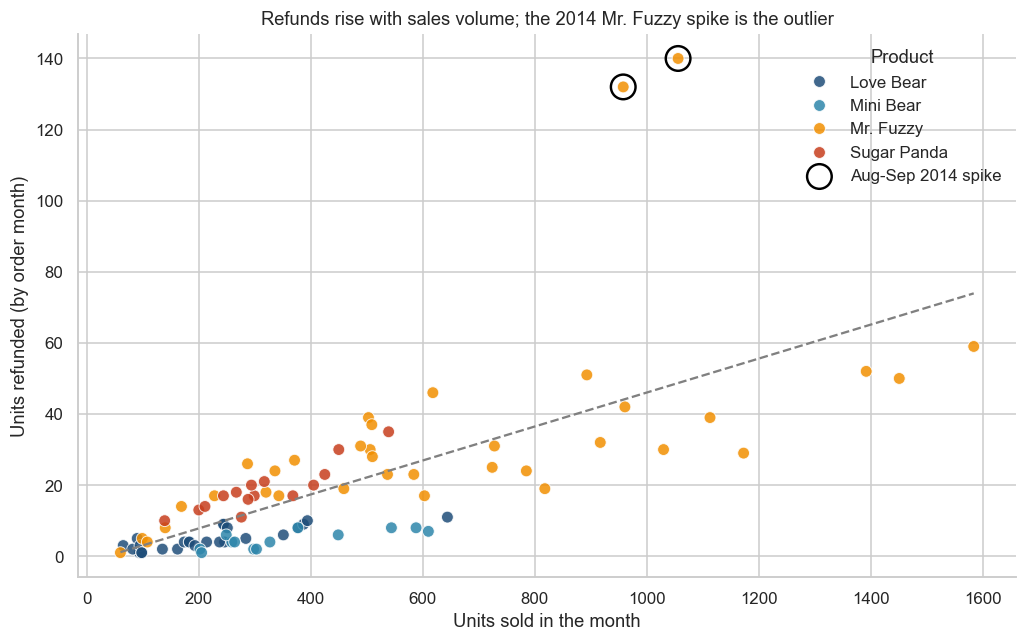

In [67]:
# Create the scatter plot of units sold versus units refunded
fig, ax = plt.subplots(figsize=(9.5, 6))
# Draw one point per product-month, coloured by product
sns.scatterplot(data=pm, x="units", y="refunded", hue="short_name", palette=PALETTE[:4], s=60, alpha=0.85, ax=ax)
# Highlight the Aug-Sep 2014 Mr. Fuzzy refund spike
spk = pm[(pm["short_name"] == "Mr. Fuzzy") & (pm["month"].isin(spike.index))]
# Circle the two spike points
ax.scatter(spk["units"], spk["refunded"], s=260, facecolors="none", edgecolors="black", linewidths=1.6, label="Aug-Sep 2014 spike")
# Overall linear trend line (refunds scale with sales)
slope, intercept = np.polyfit(pm["units"], pm["refunded"], 1)
# Draw the trend line
xs = np.linspace(pm["units"].min(), pm["units"].max(), 50)
# Plot the line
ax.plot(xs, intercept + slope * xs, ls="--", color="grey", lw=1.5)
# Add title and axis labels
ax.set(title="Refunds rise with sales volume; the 2014 Mr. Fuzzy spike is the outlier", xlabel="Units sold in the month", ylabel="Units refunded (by order month)")
# Show the legend
ax.legend(title="Product", frameon=False)
# Save and show the figure
save_fig("fig13_sales_vs_refunds")

**Interpretation**
- **Refunds scale with sales** (units sold vs units refunded: r = 0.69), which is expected: a bigger product sells more and so is refunded more often in absolute numbers.
- The **refund rate**, however, is **not** the same for every product: a chi-square test of independence is highly significant (chi-square = 246, p < 0.001, Cramer's V = 0.08, a small effect in statistical terms but commercially meaningful because refund rates range from 1.3% to 6.0%). Sugar Panda and Mr. Fuzzy have more refunds than expected, Love Bear and Mini Bear far fewer.
- Selling more does **not** significantly worsen the refund rate (Spearman rho between monthly volume and refund rate = 0.19, p = 0.08), so the refund rate is driven by the *product* and by specific episodes (the Mr. Fuzzy spike circled in the chart), not by sales volume.
- Cross-sell items are refunded at 2.5% versus 4.4% for primary items, so add-on sales are **not** causing extra returns. (This is partly because the most commonly added item, Mini Bear, has the lowest refund rate of all products.)

## 3.5 Hypothesis tests: are the differences real?
We test the main differences found in Task 2 at a 5% significance level (alpha = 0.05). For comparing conversion rates we use a chi-square test on counts; for daily revenue, which is not normally distributed, we use the Mann-Whitney U test. Observational data cannot prove causation, but A/B tests (billing and landing pages) were run concurrently and carry stronger evidence.

In [68]:
# List that will collect one row per hypothesis test
TESTS = []

def p_text(p):
    """Format a p-value for a table."""
    # Very small p-values are shown as "<0.001"
    return "<0.001" if p < 0.001 else f"{p:.3f}"

def two_prop_test(name, a_label, a_success, a_n, b_label, b_success, b_n):
    """Chi-square test for the difference between two proportions; adds a row to TESTS."""
    # Build the 2x2 table of successes and failures
    table = np.array([[a_success, a_n - a_success], [b_success, b_n - b_success]])
    # Run the chi-square test of independence
    res = stats.chi2_contingency(table)
    # Observed proportions
    pa, pb = a_success / a_n, b_success / b_n
    # Standard error of the difference (normal approximation)
    se = np.sqrt(pa * (1 - pa) / a_n + pb * (1 - pb) / b_n)
    # 95% confidence interval of the difference in percentage points
    lo, hi = (pa - pb - 1.96 * se) * 100, (pa - pb + 1.96 * se) * 100
    # Store the result
    TESTS.append({"hypothesis": name, "test": "Chi-square (2 proportions)", "statistic": res.statistic, "p_value": p_text(res.pvalue),
                  "effect": f"{a_label} {pa*100:.1f}% vs {b_label} {pb*100:.1f}% (diff {100*(pa-pb):+.1f} pp, 95% CI {lo:+.1f} to {hi:+.1f})",
                  "significant": "Yes" if res.pvalue < 0.05 else "No"})
    # Return the raw p-value for later use
    return res.pvalue

# Desktop vs mobile conversion
dsk, mob = sessions[sessions["device_type"] == "Desktop"], sessions[sessions["device_type"] == "Mobile"]
# Test 1
p_dev = two_prop_test("Desktop and mobile convert equally", "Desktop", dsk["converted"].sum(), len(dsk), "Mobile", mob["converted"].sum(), len(mob))
# New vs returning conversion (all traffic)
new_s, ret_s = sessions[sessions["visitor_type"] == "New"], sessions[sessions["visitor_type"] == "Returning"]
# Test 2
p_vis = two_prop_test("New and returning visitors convert equally (all traffic)", "Returning", ret_s["converted"].sum(), len(ret_s), "New", new_s["converted"].sum(), len(new_s))
# New vs returning inside the same brand-aware channels
sh_new, sh_ret = shared[shared["visitor_type"] == "New"], shared[shared["visitor_type"] == "Returning"]
# Test 3
p_vis2 = two_prop_test("New and returning convert equally (same channels only)", "Returning", sh_ret["converted"].sum(), len(sh_ret), "New", sh_new["converted"].sum(), len(sh_new))
# Google vs Bing non-brand conversion
g_s, b_s = sessions[sessions["channel"] == "Google nonbrand"], sessions[sessions["channel"] == "Bing nonbrand"]
# Test 4
p_gb = two_prop_test("Google and Bing non-brand convert equally", "Bing", b_s["converted"].sum(), len(b_s), "Google", g_s["converted"].sum(), len(g_s))
# Socialbook vs Google non-brand conversion
so_s = sessions[sessions["channel"] == "Social (Socialbook)"]
# Test 5
p_soc = two_prop_test("Socialbook and Google non-brand convert equally", "Socialbook", so_s["converted"].sum(), len(so_s), "Google", g_s["converted"].sum(), len(g_s))
# Billing page A/B test (concurrent period)
b1, b2 = bill_tbl.set_index("pageview_url").loc["/billing"], bill_tbl.set_index("pageview_url").loc["/billing-2"]
# Test 6
p_bill = two_prop_test("Billing page versions complete orders equally (A/B)", "/billing-2", b2["orders"], b2["sessions"], "/billing", b1["orders"], b1["sessions"])
# Landing page A/B test (concurrent period)
l2, l5 = lander_ab.set_index("landing_page").loc["/lander-2"], lander_ab.set_index("landing_page").loc["/lander-5"]
# Test 7
p_land = two_prop_test("/lander-2 and /lander-5 convert equally (desktop, concurrent)", "/lander-5", l5["orders"], l5["sessions"], "/lander-2", l2["orders"], l2["sessions"])
# Mr. Fuzzy refund spike versus the surrounding baseline
fz = items[(items["short_name"] == "Mr. Fuzzy") & (items["month"] >= "2014-01-01") & (items["month"] <= "2015-02-01")]
# Items inside the spike months
fz_spike, fz_base = fz[fz["month"].isin(spike.index)], fz[~fz["month"].isin(spike.index)]
# Test 8
p_spike = two_prop_test("Mr. Fuzzy refund rate in Aug-Sep 2014 equals other months", "Aug-Sep 2014", fz_spike["is_refunded"].sum(), len(fz_spike), "other months", fz_base["is_refunded"].sum(), len(fz_base))
# Cross-sell vs primary item refund rate
pr, cs = post_items[post_items["item_role"] == "Primary item"], post_items[post_items["item_role"] == "Cross-sell item"]
# Test 9
p_role = two_prop_test("Cross-sell and primary items are refunded equally", "Cross-sell", cs["is_refunded"].sum(), len(cs), "Primary", pr["is_refunded"].sum(), len(pr))

In [69]:
# Test 10: conversion rate differs across the six channels (chi-square on a 6 x 2 table)
ch_table = sessions.groupby("channel")["converted"].agg(["sum", "count"])
# Build the observed table: orders and non-orders per channel
obs = np.column_stack([ch_table["sum"], ch_table["count"] - ch_table["sum"]])
# Run the test
res_ch = stats.chi2_contingency(obs)
# Store the result
TESTS.append({"hypothesis": "All six channels convert equally", "test": "Chi-square (6 x 2)", "statistic": res_ch.statistic, "p_value": p_text(res_ch.pvalue),
              "effect": f"CVR from {ch_table['sum'].div(ch_table['count']).min()*100:.1f}% to {ch_table['sum'].div(ch_table['count']).max()*100:.1f}%", "significant": "Yes" if res_ch.pvalue < 0.05 else "No"})
# Test 11: product refund rates are equal (from Section 3.4)
TESTS.append({"hypothesis": "All four products have the same refund rate", "test": "Chi-square (4 x 2)", "statistic": chi.statistic, "p_value": p_text(chi.pvalue),
              "effect": f"Refund rate from {prod['refund_rate_pct'].min():.1f}% to {prod['refund_rate_pct'].max():.1f}% (Cramer's V = {cramers_v:.2f})", "significant": "Yes" if chi.pvalue < 0.05 else "No"})
# Test 12: weekday vs weekend daily revenue in 2014 (Mann-Whitney)
TESTS.append({"hypothesis": "Weekday and weekend daily revenue are equal (2014)", "test": "Mann-Whitney U", "statistic": mw_week.statistic, "p_value": p_text(mw_week.pvalue),
              "effect": f"Weekday {money(wd.mean())}/day vs weekend {money(we.mean())}/day", "significant": "Yes" if mw_week.pvalue < 0.05 else "No"})
# Test 13: Nov-Dec 2014 daily revenue higher than Sep-Oct 2014 (Mann-Whitney)
mw_hol = stats.mannwhitneyu(period(2014, [11, 12]), period(2014, [9, 10]), alternative="two-sided")
# Store the result
TESTS.append({"hypothesis": "Nov-Dec and Sep-Oct daily revenue are equal (2014)", "test": "Mann-Whitney U", "statistic": mw_hol.statistic, "p_value": p_text(mw_hol.pvalue),
              "effect": f"Nov-Dec {money(season.loc[2014, 'nov_dec_daily_rev'])}/day vs Sep-Oct {money(season.loc[2014, 'sep_oct_daily_rev'])}/day", "significant": "Yes" if mw_hol.pvalue < 0.05 else "No"})
# Test 14: no linear relationship between daily sessions and orders (Pearson)
TESTS.append({"hypothesis": "Daily sessions and orders are uncorrelated", "test": "Pearson correlation", "statistic": pear.statistic, "p_value": p_text(pear.pvalue),
              "effect": f"r = {pear.statistic:.2f}; {reg.slope*100:.1f} extra orders per 100 sessions", "significant": "Yes" if pear.pvalue < 0.05 else "No"})
# Convert the list of tests into a DataFrame
tests = pd.DataFrame(TESTS)
# Show every column completely (the effect text is long)
with pd.option_context("display.max_colwidth", 120):
    # Display the hypothesis-test summary
    display(tests)
# Store the key results for the narrative
M.update(p_gb=p_gb, p_vis2=p_vis2, p_land=p_land, p_bill=p_bill, p_soc=p_soc, p_role=p_role, p_spike=p_spike,
         n_tests=len(tests), n_sig=int((tests["significant"] == "Yes").sum()))

,hypothesis,test,statistic,p_value,effect,significant
0,Desktop and mobile convert equally,Chi-square (2 proportions),"4,638.43",<0.001,"Desktop 8.5% vs Mobile 3.1% (diff +5.4 pp, 95% CI +5.3 to +5.5)",Yes
1,New and returning visitors convert equally (all traffic),Chi-square (2 proportions),146.15,<0.001,"Returning 7.8% vs New 6.6% (diff +1.2 pp, 95% CI +1.0 to +1.4)",Yes
2,New and returning convert equally (same channels only),Chi-square (2 proportions),34.96,<0.001,"Returning 7.8% vs New 6.9% (diff +0.9 pp, 95% CI +0.6 to +1.2)",Yes
3,Google and Bing non-brand convert equally,Chi-square (2 proportions),6.37,0.012,"Bing 7.0% vs Google 6.7% (diff +0.3 pp, 95% CI +0.1 to +0.5)",Yes
4,Socialbook and Google non-brand convert equally,Chi-square (2 proportions),199.88,<0.001,"Socialbook 3.2% vs Google 6.7% (diff -3.4 pp, 95% CI -3.8 to -3.1)",Yes
5,Billing page versions complete orders equally (A/B),Chi-square (2 proportions),95.77,<0.001,"/billing-2 62.1% vs /billing 45.1% (diff +17.0 pp, 95% CI +13.7 to +20.3)",Yes
6,"/lander-2 and /lander-5 convert equally (desktop, concurrent)",Chi-square (2 proportions),19.85,<0.001,"/lander-5 10.1% vs /lander-2 8.4% (diff +1.7 pp, 95% CI +1.0 to +2.5)",Yes
7,Mr. Fuzzy refund rate in Aug-Sep 2014 equals other months,Chi-square (2 proportions),350.83,<0.001,"Aug-Sep 2014 13.5% vs other months 3.7% (diff +9.8 pp, 95% CI +8.3 to +11.4)",Yes
8,Cross-sell and primary items are refunded equally,Chi-square (2 proportions),55.83,<0.001,"Cross-sell 2.5% vs Primary 4.4% (diff -1.9 pp, 95% CI -2.3 to -1.5)",Yes
9,All six channels convert equally,Chi-square (6 x 2),332.39,<0.001,CVR from 3.2% to 7.8%,Yes


**Reading the test table**
- **All 14 of 14 tests are statistically significant** (p < 0.05): the differences found in Task 2 are real patterns and not random noise.
- **Size matters more than significance.** With samples this large, even tiny differences become "significant", so the effect column is what counts. Large, commercially important effects: desktop vs mobile (+5.4 pp), the new billing page (+17 pp), Socialbook vs Google (-3.4 pp), the Mr. Fuzzy refund spike (+9.8 pp). A small effect: Bing vs Google non-brand is detectable (p = 0.012) but only a fraction of a percentage point, so the two search engines are close in quality.
- **Returning visitors keep a real, modest edge** even inside the same channels (p = <0.001), so it is not only a channel-mix artefact.
- The **billing page and landing page** results come from tests where both versions ran at the same time with an almost even traffic split, so they are the most trustworthy evidence of cause and effect in this analysis.

## 3.6 Visualisations created
The deliverable requires **at least six meaningful visualisations**. The notebook produced the following charts, all saved as PNG files in the `figures` folder:

In [70]:
# List every chart file created in the figures folder
figure_files = sorted(f for f in os.listdir(FIG_DIR) if f.endswith(".png"))
# Print the number of charts
print(f"{len(figure_files)} visualisations saved:")
# Print each file name
for f in figure_files:
    # One chart per line
    print("  -", f)
# Verify that the minimum of six visualisations is met
assert len(figure_files) >= 6, "Fewer than six visualisations were created"
# Store the chart count
M["n_figures"] = len(figure_files)

13 visualisations saved:
  - fig01_monthly_revenue_trend.png
  - fig02_revenue_by_product.png
  - fig03_orders_weekday_hour_heatmap.png
  - fig04_cross_sell_and_aov.png
  - fig05_channels_sessions_and_conversion.png
  - fig06_mobile_vs_desktop.png
  - fig07_conversion_funnel_and_trend.png
  - fig08_landing_pages_by_device.png
  - fig09_refunds_by_product.png
  - fig10_new_vs_returning.png
  - fig11_traffic_vs_orders.png
  - fig12_period_comparison.png
  - fig13_sales_vs_refunds.png


---
# Task 4: Interpretation and Recommendations
Here we combine the evidence into **seven business insights**. To judge how much each opportunity might be worth, we first compute simple *what-if sensitivities* from the data. They are illustrations based on 2014 volumes, **not forecasts**.

In [71]:
# Sessions and orders of the last complete year (2014) used as the volume base for the what-if calculations
s14 = sessions[sessions["year"] == 2014]
# Number of orders in 2014
o14 = (orders["year"] == 2014).sum()
# 1) Each +1 percentage point of MOBILE conversion, on 2014 mobile sessions, at the mobile average order value
mobile_1pp = (s14["device_type"] == "Mobile").sum() * 0.01 * M["mobile_aov"]
# 2) Each +1 percentage point of ALL-traffic conversion on 2014 sessions at the 2014 average order value
overall_1pp = len(s14) * 0.01 * M["aov_2014"]
# 3) Each +1 percentage point of orders that contain a second item (extra value of a 2-item order over a 1-item order)
xsell_1pp = o14 * 0.01 * (M["aov_double"] - M["aov_single"])
# 4) Each +1 percentage point of customers who buy a second time, at the average order value
retention_1pp = M["customers"] * 0.01 * M["aov_total"]
# 5) Revenue-per-session gap between Socialbook and Google non-brand, applied to 10,000 sessions
social_gap_10k = (M["g_nb_rps"] - M["social_rps"]) * 10000
# 6) Sugar Panda refunds if its refund rate matched Love Bear's (the next-lowest-volume premium product)
panda_saving = prod.set_index("short_name").loc["Sugar Panda", "refunds"] * (1 - M["love_refund"] / M["panda_refund"])
# Collect the sensitivities in one table
sens = pd.DataFrame([
    ["Mobile conversion +1 pp", "2014 mobile sessions x 1% x mobile AOV", mobile_1pp, "per year"],
    ["Overall conversion +1 pp", "2014 sessions x 1% x average order value", overall_1pp, "per year"],
    ["Cross-sell rate +1 pp", "2014 orders x 1% x (2-item AOV - 1-item AOV)", xsell_1pp, "per year"],
    ["Repeat buyers +1 pp", "all customers x 1% x average order value", retention_1pp, "over 3 years"],
    ["Socialbook quality = Google non-brand", "revenue-per-session gap x 10,000 sessions", social_gap_10k, "per 10,000 sessions"],
    ["Sugar Panda refund rate = Love Bear rate", "Sugar Panda refund dollars x share avoided", panda_saving, "over 3 years"],
], columns=["lever", "assumption", "revenue_or_saving_usd", "period"])
# Display the what-if table
display(sens)
# Store the values for the narrative
M.update(mobile_1pp=mobile_1pp, overall_1pp=overall_1pp, xsell_1pp=xsell_1pp, retention_1pp=retention_1pp, social_gap_10k=social_gap_10k, panda_saving=panda_saving,
         mini_attach=attach.loc["Mini Bear", "cross_sell_rate_pct"] / 100, love_attach=attach.loc["Love Bear", "cross_sell_rate_pct"] / 100)

,lever,assumption,revenue_or_saving_usd,period
0,Mobile conversion +1 pp,2014 mobile sessions x 1% x mobile AOV,"47,131.38",per year
1,Overall conversion +1 pp,2014 sessions x 1% x average order value,"148,915.51",per year
2,Cross-sell rate +1 pp,2014 orders x 1% x (2-item AOV - 1-item AOV),"6,498.78",per year
3,Repeat buyers +1 pp,all customers x 1% x average order value,"19,014.95",over 3 years
4,Socialbook quality = Google non-brand,"revenue-per-session gap x 10,000 sessions","18,940.95","per 10,000 sessions"
5,Sugar Panda refund rate = Love Bear rate,Sugar Panda refund dollars x share avoided,"8,740.41",over 3 years


## 4.1 Seven evidence-based business insights

### Insight 1 - Growth is strong, traffic-driven and seasonal
- **Evidence:** gross revenue grew +204% in 2013 and +174% in 2014 (to $1,075,612), and early-2015 revenue is still +108% versus the same period of 2014. Growth came from both more traffic (sessions: 112,781 to 233,422) and better conversion (4.1% to 7.2%). Daily sessions explain 91% of the variation in daily orders. November-December revenue per day runs +39% above September-October, and a weekend day earns only 44% of a weekday.
- **Recommendation:** plan stock, customer support and ad budgets for the Q4 peak from September; test weekend-specific offers or emails to lift the weaker days.

### Insight 2 - Cross-selling is the cheapest way to raise order value
- **Evidence:** since the second-item option launched (Sep 2013), 34% of 2014 orders contained two items, worth $89.25 versus $50.71 for one item, which lifted average order value from $49.99 to $63.80. Attach rates differ widely by the primary product: 34% for Sugar Panda, but only 22% for Love Bear and 8% for Mini Bear. Cross-sell items are not returned more often (2.5% refund rate vs 4.4%).
- **Recommendation:** extend and test the add-on prompt for the low-attach products and promote Mini Bear (the most added item and one of the two best-margin products) as the default companion. Every +1 percentage point of orders with a second item is worth about **$6,499 a year** at 2014 volumes.

### Insight 3 - Mobile is the biggest untapped conversion opportunity
- **Evidence:** mobile brings 31% of sessions but only 14% of orders. Mobile converts at 3.1% versus 8.5% on desktop (2.8x gap, p < 0.001) with the same order value. Mobile conversion plateaued after 2013 (3.1% to 3.5%) while desktop kept rising (8.0% to 10.6%), and mobile visitors lag at every funnel stage, most visibly when moving into a product page (84% of desktop vs 68% of mobile sessions) and into billing (83% vs 71%).
- **Recommendation:** treat mobile as its own product: simplify the mobile product, cart and checkout pages, improve load speed, and run mobile-only A/B tests. Each +1 percentage point of mobile conversion is worth about **$47,131 a year**.

### Insight 4 - Controlled tests have produced the biggest gains, and the funnel still leaks
- **Evidence:** the new billing page converted 62.1% of billing sessions versus 45.1% for the old one (+17 pp, concurrent test, p < 0.001) and the `/lander-5` desktop landing page beat `/lander-2` (10.1% vs 8.4% conversion). The largest remaining leaks are product page to cart (55% leave), landing page to products page (45% leave) and billing to order (38% leave). 45% of sessions bounce after one page.
- **Recommendation:** keep the experimentation habit and aim the next tests at the product page (price/imagery/reviews), the cart (shipping cost visibility, trust signals) and the billing step. One extra percentage point of overall conversion would add about **$148,916 a year**.

### Insight 5 - Channel quality varies and traffic is concentrated
- **Evidence:** Google non-brand provides 60% of sessions (a concentration risk). Brand-aware traffic (direct, organic, paid brand) grew 7.9x from 2012 to 2014 against 2.8x for Google non-brand and converts better (7.2% to 7.8% vs 6.7%). Socialbook converts at only 3.2% and earns $2.08 per session versus $3.98 for Google non-brand (10,000 sessions = about $18,941 less revenue). Bing non-brand is slightly better than Google non-brand (7.0% vs 6.7%).
- **Recommendation:** review or restructure the Socialbook spend, test more budget on Bing non-brand, protect brand search, and invest in organic content and CRM that feed the high-converting brand-aware audience. **Caveat:** the data contains no advertising costs, so the final budget decision must be based on cost per acquisition and return on ad spend, which should be added to the analysis.

### Insight 6 - Refunds are a product-quality issue with episodes worth monitoring
- **Evidence:** 4.3% of units are refunded ($85,339, 4.4% of revenue). Refund rates differ significantly by product: Sugar Panda 6.0%, Mr. Fuzzy 5.1%, Love Bear 2.2%, Mini Bear 1.3%. In August-September 2014 Mr. Fuzzy refunds spiked to about 14% (normal: 3.7%), costing roughly $9,909 extra. All refunds are full refunds and arrive a median of 9 days after the order.
- **Recommendation:** add a weekly refund-rate alert per product (for example, more than twice the product's normal rate) so a quality problem is caught within weeks, work with suppliers on batch-level quality checks, and investigate why Sugar Panda is refunded most often (description, sizing, quality). Bringing the Sugar Panda refund rate to the Love Bear level would have saved about **$8,740** over the three years.

### Insight 7 - Customers need more than one visit, but very few buy twice
- **Evidence:** 19% of orders are placed on a return visit, and returning visitors convert better than new ones even within the same channels (7.8% vs 6.9%, p < 0.001). Yet only 1.9% of customers ever place a second order (median gap 29 days). The returning share of traffic is rising (8% to 18% of sessions).
- **Recommendation:** build a retention programme: cart-abandonment and "come back" reminders for first-time visitors, plus a post-purchase email around day 25-30 (the typical repeat gap) with a bundle or birthday-gift offer. Each +1 percentage point of customers who buy again is worth about **$19,015** over three years.

## 4.2 Priority summary

| # | Opportunity | Key metric | Illustrative value | Effort |
|---|---|---|---|---|
| 3 | Fix the mobile experience | mobile conversion 3.1% vs desktop 8.5% | $47,131 per +1 pp per year | Medium |
| 4 | Keep A/B testing the funnel | 45% of product viewers reach the cart | $148,916 per +1 pp per year | Low-Medium |
| 2 | Expand cross-selling | 34% of orders have 2 items | $6,499 per +1 pp per year | Low |
| 5 | Re-balance channel spend | Socialbook 3.2% conversion | $18,941 per 10,000 sessions | Low |
| 6 | Refund early-warning and quality control | 4.4% of revenue refunded | $9,909 lost in one episode | Low |
| 7 | Retention and CRM | 1.9% repeat buyers | $19,015 per +1 pp | Medium |
| 1 | Seasonal planning | Nov-Dec +39% | Avoid stock-outs in the peak | Low |

## 4.3 Limitations and next steps
- **Truncated pageview file:** page-level results (funnel, landing pages, billing test) use 89.2% of sessions (to 16 Jan 2015). Re-export the file in full (not through Excel) to refresh them.
- **Partial years:** 2012 (from 19 March) and 2015 (to 19 March) are incomplete, so trends use complete months and like-for-like windows.
- **No cost or customer data:** there are no advertising costs, so return on ad spend and customer acquisition cost cannot be calculated, and no demographics to segment customers.
- **Observational data:** except for the concurrent A/B tests, relationships are associations. The what-if values are sensitivities, not forecasts.
- **Next steps:** add marketing cost data, build a cohort/lifetime-value analysis, forecast Q4 demand, and test the recommended changes with controlled experiments.

## 4.4 Save the key results
The final cell saves the key numbers and summary tables so that the report and presentation use exactly the same figures as this notebook.